# Liveness training and evaluation

Liveness checks help prevent a photo or screen replay from being accepted as a live person at attendance. This notebook compares four ResNet-18 configurations: binary classification alone, with semantic labels, with geometric pseudo-targets, and with both. All first trained for 15 epochs; semantic/full then continued to 25.

AENet full was selected at epoch 18. After crop-review exclusions, its public-test ACER is 6.176%, including 12.222% spoof acceptance. All 25 recorded camera trials were classified correctly, but this bounded sample does not establish general deployment accuracy. Sections 14–16 show the comparisons, error rates and example crops; section 5.1 defines the retained dataset.

## Choose an action

The default is `ACTION = "inspect"`: read saved results without training or model inference. Existing outputs can also be read without running cells.

| Action | Work | Colab runtime |
| --- | --- | --- |
| inspect | Render saved metrics, curves and examples | CPU |
| prepare | Copy/check existing caches | CPU |
| train | Start/resume the declared experiment | GPU |
| inference | Score camera clips | GPU; local CLI also supports CPU |
| evaluate | Score public-test images at the frozen threshold | GPU |

<details>
<summary>Local execution</summary>

With the [project environment](../docs/setup.md) active and the repository as working directory:

```sh
python scripts/run_liveness_notebook.py --action inspect
```

The plain-Python runner retains tables/figures without IPython or Google authentication. Use the [inference guide](../docs/liveness-training-and-evaluation.md#portable-inference-and-saved-inspection) for your own images or MP4s.

</details>

<details>
<summary>Google Colab execution</summary>

Run the Drive setup with the shared project folder ID, then choose ACTION in section 3. Commenters read shared inputs and write new outputs to private MyDrive. Prepare uses CPU; training, camera inference and public-test evaluation use the declared GPU route. Native revised Colab execution remains unverified.

</details>

## 1\. Research basis

The configuration is based on Yuanhan Zhang and colleagues’ **CelebA-Spoof: Large-Scale Face Anti-Spoofing Dataset with Rich Annotations**, published at ECCV 2020. The [research article, arXiv version 3](https://arxiv.org/abs/2007.12342v3), introduces the dataset and Auxiliary Information Embedding Network (AENet), a framework that combines live/spoof classification with additional training tasks. The [authors’ source repository](https://github.com/ZhangYuanhan-AI/CelebA-Spoof) provides the released implementation and dataset information.

ResNet-18 converts each face image into a feature vector. Separate output layers, called heads, use that vector to predict live/spoof, semantic labels or geometric maps. All four configurations learn to classify faces as live or spoof. They differ in which additional tasks they learn.


## 2\. Notebook setup



### 2\.1 Runtime imports

The notebook uses these libraries to mount Drive, verify file checksums and launch subprocesses.


In [ ]:
import hashlib
import importlib.util
import json
import shutil
import subprocess
import sys
import tempfile
import time
from datetime import UTC, datetime
from html import escape
from importlib.metadata import PackageNotFoundError, version
from pathlib import Path
from urllib.parse import urlparse

In [ ]:
IS_COLAB = sys.modules.get("google.colab") is not None
if IS_COLAB:
    from IPython.display import HTML, display
else:
    LOCAL_PROJECT = Path(globals().get("LOCAL_PROJECT", Path.cwd())).resolve()
    if LOCAL_PROJECT.name == "notebooks":
        LOCAL_PROJECT = LOCAL_PROJECT.parent
    sys.path.insert(0, str(LOCAL_PROJECT / "src"))
    from facial_attendance.notebook_runtime import HTML, display

### 2\.2 Table formatting

The shared renderer formats the notebook’s HTML tables, including the per-clip camera results.


In [ ]:
def display_table(headers, rows):
    """Render escaped HTML with table spacing and theme-aware row colors."""
    wrapper_style = "padding: 2px 0 4px; overflow-x: auto;"
    table_style = "border-collapse: collapse; margin: 0;"
    cell_style = (
        "border: 1px solid color-mix(in srgb, currentColor 26%, transparent); "
        "padding: 6px 10px; text-align: left;"
    )
    header_style = (
        cell_style + " background: color-mix(in srgb, currentColor 13%, transparent);"
    )
    stripe_style = "background: color-mix(in srgb, currentColor 7%, transparent);"
    heading = "".join(
        f'<th scope="col" style="{header_style}">{escape(str(value))}</th>'
        for value in headers
    )
    body = []
    for index, row in enumerate(rows, start=1):
        row_style = stripe_style if index % 2 == 0 else ""
        cells = "".join(
            f'<td style="{cell_style}">{escape(str(value))}</td>' for value in row
        )
        body.append(f'<tr style="{row_style}">{cells}</tr>')
    display(
        HTML(
            f'<div style="{wrapper_style}"><table style="{table_style}">'
            f"<thead><tr>{heading}</tr></thead>"
            f"<tbody>{''.join(body)}</tbody></table></div>"
        )
    )

### 2\.3 Library versions

This list shows the libraries loaded by the notebook. The GPU workflow checks the separate Python environment that runs the model before it starts inference or training.


In [ ]:
versions = [["Python standard library", sys.version.split()[0]]]
for module, distribution in (
    ("IPython", "ipython"),
    ("google.colab", "google-colab"),
    ("googleapiclient", "google-api-python-client"),
):
    try:
        installed_version = version(distribution)
    except PackageNotFoundError:
        installed_version = "Package metadata unavailable"
    versions.append([module, installed_version])

display_table(["Imported library", "Version"], versions)

Imported library,Version
Python standard library,3.13.16
IPython,Package metadata unavailable
google.colab,Package metadata unavailable
googleapiclient,Package metadata unavailable


### 2\.4 Plotting tools

These helpers read archived scores and render labelled figures. They do not run training, inference or model selection. The figures appear beside their corresponding validation, public-test and error-analysis results.

In [ ]:
import base64
import csv
import io

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from sklearn.metrics import roc_auc_score, roc_curve

Plots use consistent text sizes and a white background. Rendering helpers are loaded from checksum-verified project source beside the first validation comparison.

In [ ]:
plt.rcParams.update(
    {
        "font.size": 11,
        "axes.titlesize": 12,
        "axes.labelsize": 11,
        "legend.fontsize": 10,
        "figure.facecolor": "white",
    }
)

In [ ]:
# Join predictions by stable source identity; row order alone is not evidence of alignment.
def visual_read_json(path):
    return json.loads(path.read_text(encoding="utf-8"))


def visual_child(root, relative):
    path = (root / relative).resolve()
    if not path.is_relative_to(root.resolve()):
        raise ValueError("Analysis evidence path escapes its root")
    return path


def visual_predictions(path):
    with path.open(encoding="utf-8", newline="") as stream:
        rows = list(csv.DictReader(stream))
    if not rows or len({row["relative_path"] for row in rows}) != len(rows):
        raise ValueError("Empty or duplicate prediction identities")
    rows.sort(key=lambda row: row["relative_path"])
    labels = np.array([int(row["binary_label"]) for row in rows])
    scores = np.array([float(row["spoof_score"]) for row in rows])
    if set(labels) != {0, 1} or not np.all(np.isfinite(scores)):
        raise ValueError("Predictions require both classes and finite scores")
    if np.any((scores < 0) | (scores > 1)):
        raise ValueError("Spoof scores must be between zero and one")
    return rows, labels, scores

## 3\. Run configuration

The next cell selects the task, project inputs and saved results:

- `PROJECT_FOLDER` is the URL or ID of the project folder on Drive. Keep it when using the same shared project. If you copy the project, use the copied folder’s URL or ID.
- `ACTION` chooses the task: inspect reads saved results, inference scores camera clips, and evaluate scores the public test. For training, prepare copies and checks input caches; train starts or resumes training.
- `TARGET_EPOCHS` sets when training stops. A value of 25 means stop at epoch 25, not run 25 more epochs. Other actions ignore this setting.
- `TRAINING_OUTPUT_NAME` identifies the experiment’s checkpoint and results folder. Keep liveness-continuation to read the supplied experiment’s saved results. New results are saved in the shared project if its output folder is writable; otherwise, they go to your own MyDrive.


In [ ]:
PROJECT_FOLDER = (
    "https://drive.google.com/drive/folders/1JSB858oMc2k9uaO1o8ZNma32zTySe1dC"
)
ACTION = globals().get("ACTION", "inspect")
TARGET_EPOCHS = 25
TRAINING_OUTPUT_NAME = "liveness-continuation"

# Reuse the saved auxiliary report by default; opt in only to regenerate it.
RUN_AUXILIARY_ANALYSIS = False
# Inspect renders saved evidence; opt in to repeat raw-source pixel verification.
VERIFY_SOURCE_CROPS = False

## 4\. Drive setup

Sign in with the Google account that has the project files. This step mounts Drive so Colab can read and save files, and authenticates access to the Drive API.


Accept the shared project folder URL or its ID. Notebook URLs are rejected so copying a notebook cannot silently select a different project.

In [ ]:
def drive_folder_id(value):
    "Accept a folder URL/ID without inferring location from a notebook."
    parsed = urlparse(value.strip())
    identifier = value.strip()
    if parsed.scheme or parsed.netloc:
        if parsed.scheme != "https" or parsed.netloc != "drive.google.com":
            raise ValueError("Supply a Google Drive folder URL or folder ID")
        parts = parsed.path.rstrip("/").split("/")
        if len(parts) < 2 or parts[-2] != "folders":
            raise ValueError("Use the project folder URL, not a notebook URL")
        identifier = parts[-1]
    if not identifier or any(
        c not in "abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789_-"
        for c in identifier
    ):
        raise ValueError("Invalid Google Drive folder ID")
    return identifier

Folder and shortcut searches read every API page. Identity comes from IDs; folder names alone do not identify a project.

In [ ]:
def drive_items(api, query):
    "Read every page so shortcut reuse does not depend on listing order."
    items, token = [], None
    while True:
        page = (
            api.files()
            .list(
                q="trashed=false and " + query,
                pageToken=token,
                fields="nextPageToken,files(id,name,parents,mimeType,shortcutDetails)",
                supportsAllDrives=True,
                includeItemsFromAllDrives=True,
            )
            .execute()
        )
        items.extend(page.get("files", []))
        token = page.get("nextPageToken")
        if not token:
            return items


def named_children(api, parent, name):
    "Escape Drive query syntax for names containing quotes or backslashes."
    escaped = name.replace("\\", "\\\\").replace("'", "\\'")
    return drive_items(api, f"'{parent}' in parents and name='{escaped}'")

Check access to the folder before mounting. A missing folder or denied access receives a readable message; quota and server errors retain their original cause.

In [ ]:
if IS_COLAB:
    from googleapiclient.errors import HttpError


def drive_access_denied(error):
    "Keep quota/server failures distinct from inaccessible file IDs."
    if error.resp.status == 404:
        return True
    try:
        details = json.loads(error.content).get("error", {}).get("errors", [])
    except (TypeError, ValueError):
        return False
    reasons = {row.get("reason") for row in details}
    return error.resp.status == 403 and bool(
        reasons & {"insufficientFilePermissions", "appNotAuthorizedToFile"}
    )

Read folder metadata using the verified ID. Access errors identify the folder/account checks to make; other API failures remain visible.

In [ ]:
def drive_folder_metadata(api, folder_id):
    "Read folder capabilities without creating a writable probe."
    try:
        item = (
            api.files()
            .get(
                fileId=folder_id,
                fields="id,name,mimeType,parents,capabilities(canAddChildren)",
                supportsAllDrives=True,
            )
            .execute()
        )
    except HttpError as error:
        if drive_access_denied(error):
            raise PermissionError(
                "Folder unavailable: check its URL, the signed-in account and folder sharing permissions."
            ) from error
        raise
    if item.get("mimeType") != "application/vnd.google-apps.folder":
        raise ValueError("The supplied ID must identify a folder")
    return item

Follow accessible parent folders to MyDrive. Ambiguous or unsafe path components use an ID-based shortcut instead; the owner’s private ancestors are not required.

In [ ]:
def my_drive_folder_path(api, folder_id, root_id):
    "Return an unambiguous path within this account's MyDrive, if any."
    names, visited = [], set()
    while folder_id != root_id:
        if folder_id in visited:
            raise ValueError("Drive folder ancestry contains a cycle")
        visited.add(folder_id)
        try:
            item = (
                api.files()
                .get(fileId=folder_id, fields="id,name,parents", supportsAllDrives=True)
                .execute()
            )
        except HttpError as error:
            if drive_access_denied(error):
                return None
            raise
        name, parents = item["name"], item.get("parents", [])
        if name in ("", ".", "..") or "/" in name or len(parents) != 1:
            return None
        if len(named_children(api, parents[0], name)) != 1:
            return None
        names.append(name)
        folder_id = parents[0]
    return tuple(reversed(names))

Reuse an existing shortcut even when it is inside a MyDrive subfolder. Create a new shortcut only when neither a direct path nor an accessible shortcut exists.

In [ ]:
def drive_shortcut_path(api, folder_id, root_id):
    "Reuse by target ID, including shortcuts nested inside MyDrive."
    query = "mimeType='application/vnd.google-apps.shortcut' and shortcutDetails.targetMimeType='application/vnd.google-apps.folder'"
    for item in drive_items(api, query):
        if item.get("shortcutDetails", {}).get("targetId") == folder_id:
            path = my_drive_folder_path(api, item["id"], root_id)
            if path is not None:
                return path
    alias, number = "colab-folder-" + folder_id, 0
    while named_children(api, root_id, alias):
        number += 1
        alias = f"colab-folder-{folder_id}-{number}"
    api.files().create(
        body={
            "name": alias,
            "mimeType": "application/vnd.google-apps.shortcut",
            "parents": [root_id],
            "shortcutDetails": {"targetId": folder_id},
        },
        fields="id",
    ).execute()
    return (alias,)

Combine folder validation and path selection. Reuse a direct MyDrive path first, then a matching shortcut.

In [ ]:
def resolve_drive_folder(api, value, root_id):
    "Validate the folder before selecting a direct path or shortcut."
    item = drive_folder_metadata(api, drive_folder_id(value))
    path = my_drive_folder_path(api, item["id"], root_id)
    return item, path if path is not None else drive_shortcut_path(
        api, item["id"], root_id
    )

Commenters and viewers write to their own MyDrive/facial-attendance-outputs, separated by project ID. Existing output folders must be unambiguous and writable; no probe files are created.

In [ ]:
def ensure_output_folder(api, parent, name):
    "Create a personal output folder or verify its ability to accept files."
    matches = named_children(api, parent, name)
    if len(matches) > 1:
        raise ValueError(f"Output folder name is ambiguous: {name}")
    if matches:
        item = drive_folder_metadata(api, matches[0]["id"])
    else:
        item = (
            api.files()
            .create(
                body={
                    "name": name,
                    "mimeType": "application/vnd.google-apps.folder",
                    "parents": [parent],
                },
                fields="id,capabilities(canAddChildren)",
            )
            .execute()
        )
    if not item.get("capabilities", {}).get("canAddChildren", False):
        raise PermissionError(f"Cannot create outputs in {name}")
    return item["id"]

Use the shared project only when its existing evidence folders allow new files. Otherwise select a private output folder, leaving source code, checkpoints and shared evidence unchanged.

In [ ]:
def output_project_id(api, project, root_id, evidence_parts=("evidence", "liveness")):
    "Use private outputs when the evidence destination is not writable."
    current, writable = project, True
    for name in evidence_parts:
        writable = current.get("capabilities", {}).get("canAddChildren", False)
        if not writable:
            break
        matches = named_children(api, current["id"], name)
        if not matches:
            return project["id"]
        if len(matches) != 1:
            raise ValueError(f"Evidence folder name is ambiguous: {name}")
        current = drive_folder_metadata(api, matches[0]["id"])
    if writable and current.get("capabilities", {}).get("canAddChildren", False):
        return project["id"]
    parent = ensure_output_folder(api, root_id, "facial-attendance-outputs")
    return ensure_output_folder(api, parent, project["id"])

Drive API setup happens before mounting. Allow up to 30 seconds for each folder to become visible; an existing mount is not forcibly replaced while another operation may be using it.

In [ ]:
def wait_for_drive_folder(path):
    "Bound DriveFS propagation waits without disrupting mounted jobs."
    deadline = time.monotonic() + 30
    while time.monotonic() < deadline:
        if path.is_dir():
            return path
        time.sleep(1)
    raise FileNotFoundError(
        "Drive folder is not visible yet. Reconnect Drive and rerun setup; existing files are retained."
    )

Authenticate with the account receiving the shared project. Resolve its folder ID and output destination through the API, then mount Drive and confirm the paths are readable.

In [ ]:
if IS_COLAB:
    from google.colab import auth, drive
    from googleapiclient.discovery import build

    # No project module is needed to locate the shared inputs or private outputs.
    auth.authenticate_user()
    drive_api = build("drive", "v3", cache_discovery=False)
    root_id = drive_api.files().get(fileId="root", fields="id").execute()["id"]
    project_metadata, project_parts = resolve_drive_folder(
        drive_api, PROJECT_FOLDER, root_id
    )
    output_id = output_project_id(
        drive_api,
        project_metadata,
        root_id,
        evidence_parts=("evidence", "liveness", TRAINING_OUTPUT_NAME),
    )
    output_parts = my_drive_folder_path(drive_api, output_id, root_id)
    drive.mount("/content/drive")
    drive_root = Path("/content/drive/MyDrive")
    DRIVE_PROJECT = wait_for_drive_folder(drive_root.joinpath(*project_parts))
    OUTPUT_PROJECT = wait_for_drive_folder(drive_root.joinpath(*output_parts))
else:
    DRIVE_PROJECT = LOCAL_PROJECT
    OUTPUT_PROJECT = LOCAL_PROJECT

The Colab route validates the selected project layout and release before loading project source. Local execution uses the activated environment and the source in the project working directory.

In [ ]:
def load_project_release(project):
    "Reject missing layout or unsafe inventory before loading project code."
    required = ("src", "scripts", "configs")
    if not all((project / name).is_dir() for name in required):
        raise FileNotFoundError("Project needs src, scripts and configs folders")
    path = project / "configs/liveness-release.json"
    release = json.loads(path.read_text(encoding="utf-8"))
    if (
        release.get("schema") != "liveness-training-release-v1"
        or not isinstance(release.get("files"), dict)
        or not release["files"]
    ):
        raise ValueError("Unsupported or empty project release inventory")
    for name, record in release["files"].items():
        for relative in (name, record["delivery_path"]):
            if not (project / relative).resolve().is_relative_to(project.resolve()):
                raise ValueError("Release path escapes the project")
        if len(record["sha256"]) != 64 or any(
            c not in "0123456789abcdef" for c in record["sha256"]
        ):
            raise ValueError("Invalid release checksum")
    return release

Check each executable source file against its release checksum before staging it. Canonical paths must stay inside the selected project.

In [ ]:
def verified_source(project, record):
    "Verify declared source bytes inside the canonical project root."
    path = (project / record["delivery_path"]).resolve()
    if not path.is_relative_to(project.resolve()):
        raise ValueError("Source path escapes the project")
    content = path.read_bytes()
    if hashlib.sha256(content).hexdigest() != record["sha256"]:
        raise ValueError(f"Source checksum mismatch: {path.name}")
    return content

## 5\. Inputs and caches

Colab reuses cropped face images so training can start without decoding the source images again. When a crop has a recorded correction, training uses the corrected version. Configurations that also learn depth and reflection use a separate cache of those targets.

Before reusing a cache, the training workflow checks its accompanying JSON record to confirm that it matches the intended files and train, validation and test assignments. The release inventory tells Colab where to find the required files and gives their expected SHA-256 checksums so it can verify their contents.

The cell below reads the release inventory and sets the input paths. Cache transfer is configured before staging the verified files from Drive to the runtime.

Checksums verify which pixels were cached, not whether a supplied box selected the correct subject. The source-content review below applies a separate eligibility decision.


### 5\.1 Reviewed dataset

Review compares the supplied crop and detector crop with the original image. It excludes wrong-subject crops, tiny faces and edge fragments whose missing detail cannot be recovered by resizing. Valid print/screen attacks remain useful even without a detector match. The bounded review checked 353 prioritized cases during the three-day [Tracker allocation](../README.md#project-tracker).

| Split | Before review | Excluded | Retained |
| --- | ---: | ---: | ---: |
| Train | 444,357 | 243 | 444,114 |
| Validation | 49,504 | 25 | 49,479 |
| Test | 67,170 | 41 | 67,129 |
| ***Total*** | 561,031 | 309 | 560,722 |

Decisions follow crop content, not prediction correctness; labels and original split assignments stay fixed. The saved checkpoints predate these exclusions. Section 14.5 recalculates their metrics on retained rows, while a future filtered-data training run uses the same row indices for images, labels and teacher maps. This review does not certify unseen crop semantics or remove the model's earlier exposure.


In [ ]:
if not IS_COLAB and ACTION not in ("inspect", "inference"):
    raise ValueError(
        "Local notebook execution supports inspect and CPU inference. Use Google Colab "
        "for preparation, training and public-test evaluation."
    )
if ACTION not in ("inspect", "prepare", "train", "evaluate", "inference"):
    raise ValueError("Select inspect, prepare, train, evaluate, or inference")
release = load_project_release(DRIVE_PROJECT)
REVIEWED_VIEW = DRIVE_PROJECT / Path(release["crop_review"]["cache_view"]).parent
if ACTION == "train":
    review_record = release["files"][release["crop_review"]["cache_view"]]
    selection = json.loads(verified_source(DRIVE_PROJECT, review_record))
    if any(
        selection["splits"][split]["pending_review"]
        for split in ("train", "validation")
    ):
        raise ValueError("Resolve reviewed training/validation cases before training")
    if TRAINING_OUTPUT_NAME in ("liveness-comparison", "liveness-continuation"):
        raise ValueError(
            "Choose a separate output name for training on the filtered selection"
        )
PROJECT = Path("/content/facial-attendance") if IS_COLAB else LOCAL_PROJECT
RELEASE = DRIVE_PROJECT / "configs/liveness-release.json"
PREPARED = DRIVE_PROJECT / "data/liveness/face-cache/faces"
DECODED = PROJECT / "data/cache/liveness-faces"

## 6\. Model and training recipe

The release inventory records the recipe that the training entry point will execute. The following cell displays those settings and identifies the supplied ImageNet initialization checkpoint by checksum. It reads configuration only; it does not load model weights or allocate a GPU. Runtime source and input checks are performed before training.

ResNet-18 extracts image features from 224 × 224 RGB face crops. This backbone starts with weights learned on ImageNet; training updates those weights using CelebA-Spoof images. Color distortion varies brightness, contrast, saturation and hue during training. Each selected configuration starts from its saved epoch-15 state and trains through epoch 25.

A loss is a numerical penalty for prediction error. The optimizer adjusts weights to reduce this penalty; this experiment uses stochastic gradient descent (SGD), learning rate 0.005, momentum 0.9 and weight decay 0.0001. A random seed fixes the initial random sequence used by the experiment.


In [ ]:
experiment = dict(release["experiment"])
experiment["epochs_per_arm"] = TARGET_EPOCHS
recipe_fields = (
    "backbone",
    "initialization",
    "input_size",
    "optimizer",
    "learning_rate",
    "color_distortion",
    "epochs_per_arm",
    "batch_size",
    "precision",
    "seed",
)
print("Declared training recipe:")
print(json.dumps({name: experiment[name] for name in recipe_fields}, indent=2))
initialization = release["files"][
    "artifacts/pretrained/resnet18-imagenet1k-initialization.pth"
]
print("ImageNet initialization SHA-256:", initialization["sha256"])

Declared training recipe:
{
  "backbone": "ResNet-18",
  "initialization": "ImageNet pretrained backbone; task heads initialized for this experiment",
  "input_size": [
    224,
    224
  ],
  "optimizer": "SGD",
  "learning_rate": 0.005,
  "color_distortion": {
    "brightness": 0.3,
    "contrast": 0.3,
    "saturation": 0.2,
    "hue": 0.05
  },
  "epochs_per_arm": 25,
  "batch_size": 256,
  "precision": "FP32",
  "seed": 42
}
ImageNet initialization SHA-256: f37072fd47e89c5e827621c5baffa7500819f7896bbacec160b1a16c560e07ec


## 7\. Supervision comparison

Every configuration learns to classify images as live (0) or spoof (1). Some also learn to predict face attributes or image properties such as depth. These extra training targets are called auxiliary supervision. They help shape the image features shared by all tasks.

| Configuration | Live/spoof labels | Semantic labels | Pseudo-depth | Pseudo-reflection |
| --- | --- | --- | --- | --- |
| binary-classification | Yes | No | No | No |
| binary-semantic | Yes | Yes | No | No |
| binary-geometric | Yes | No | Yes | Yes |
| aenet-full | Yes | Yes | Yes | Yes |

The names describe which targets are enabled. Binary-semantic and binary-geometric are AENet ablation variants: an ablation removes a supervision group to examine its contribution. The geometric configuration uses depth and reflection together, so this design does not measure their individual contributions.

The next two subsections show where the extra training targets come from.


In [ ]:
ARMS = experiment["arms"]
print("Requested configurations:")
for configuration in ARMS:
    print("-", configuration)
print("Target epochs per configuration:", TARGET_EPOCHS)
print(
    "Additional epochs per configuration:",
    TARGET_EPOCHS - experiment["completed_base_epochs"],
)

Requested configurations:
- binary-semantic
- aenet-full
Target epochs per configuration: 25
Additional epochs per configuration: 10


### 7\.1 Semantic labels

Semantic labels are dataset annotations for 40 face attributes, source/spoof type and illumination. They provide training tasks in addition to live/spoof classification. A face attribute describes a property such as eyeglasses; source/spoof type distinguishes live images from attack media. The training labels encode each spoof image’s face attributes as 40 zeros. Live images use illumination class ID 0, named “No illumination” in the dataset annotation scheme.

The cell below reads one checksum-verified saved validation example to show its annotation encoding. Saved-result inspection does not open the original dataset.

The historical training runs used 444,357 training images, 49,504 validation images and 67,170 public test images. Current filtered counts are defined in section 5.1. Training updates weights, validation selects models and thresholds, and test assesses the frozen selection. Because the CelebA-Spoof authors did not publish their exact validation assignment, our team set aside part of the original training split for validation. We kept the public test split intact.



In [ ]:
# Saved examples retain their original annotation binding, so inspection does
# not require the full dataset. Live-data checks remain an explicit action.
example_path = "evidence/liveness/visual-analysis-filtered/selected-examples.json"
example_record = release["files"][example_path]
example_bytes = (DRIVE_PROJECT / example_record["delivery_path"]).read_bytes()
if hashlib.sha256(example_bytes).hexdigest() != example_record["sha256"]:
    raise ValueError("Saved validation-example checksum mismatch")
saved_examples = json.loads(example_bytes)
annotation_record = release["files"][
    "data/raw/liveness/celeba-spoof-full/project_validation.json"
]
if saved_examples["annotations_sha256"] != annotation_record["sha256"]:
    raise ValueError("Saved example belongs to different validation annotations")
example_path = min(saved_examples["examples"])
example = saved_examples["examples"][example_path]
if len(example["true_face_attributes"]) != 40:
    raise ValueError("Expected 40 CelebA-Spoof face attributes")
print(
    json.dumps(
        {
            "example_path": example_path,
            "label_source": "Checksum-verified saved validation example",
            "example_live_spoof_label": example["true_binary"],
            "face_attribute_count": len(example["true_face_attributes"]),
            "positive_face_attributes": sum(example["true_face_attributes"]),
            "source_type_id": example["true_source_type"],
            "illumination_id": example["true_illumination"],
        },
        indent=2,
    )
)
del example_bytes, saved_examples

{
  "example_path": "Data/train/1598/live/355373.jpg",
  "label_source": "Checksum-verified saved validation example",
  "example_live_spoof_label": 0,
  "face_attribute_count": 40,
  "positive_face_attributes": 10.0,
  "source_type_id": 0,
  "illumination_id": 0
}


### 7\.2 Depth and reflection targets

The geometric configurations add two tasks during training. They learn to predict depth for live faces and reflection for spoof images. To train those predictions, we first need a target for each task. PRNet estimates the depth of a live face, and the reflection-separation model from Xuaner Zhang and colleagues estimates the reflection in a spoof image. We use these estimates as training targets and call them **pseudo-labels**.

Every image has a slot for both targets in the cache. We fill the slot that has no estimate with zeros, as shown below.

| Image | Depth target | Reflection target |
| --- | --- | --- |
| Live face | PRNet estimate | Zeros |
| Spoof | Zeros | Reflection-separation estimate |

Depth takes one grid. Reflection takes three grids, one for each color channel: red, green and blue. Together, they make four grids per image. This is what the 4 means in the JSON shape [444357, 4, 14, 14]: 444,357 images, each with four grids of 14 rows by 14 columns. The JSON describes the cache. The values in the grids are stored in a separate array.

These targets guide training. In the local webcam demo, the liveness check makes its decision using the model’s live/spoof score.


In [ ]:
# The source-distributed index retains the historical receipt for inspection.
index_path = "evidence/liveness/submission-artifacts.json"
index_record = release["files"][index_path]
index_bytes = (DRIVE_PROJECT / index_record["delivery_path"]).read_bytes()
if hashlib.sha256(index_bytes).hexdigest() != index_record["sha256"]:
    raise ValueError("Artifact-index checksum mismatch")
geometry_receipt = json.loads(index_bytes)["runtime_inputs"]["geometric_targets"][
    "receipt"
]
geometry_record = release["files"]["transfer/geometric-cache/geometric-targets.npy"]
if geometry_receipt["array_sha256"] != geometry_record["sha256"]:
    raise ValueError("Saved geometric receipt differs from the release array")
print(
    json.dumps(
        {
            "completed": geometry_receipt["completed"],
            "completed_rows": geometry_receipt["completed_rows"],
            "shape": geometry_receipt["bindings"]["shape"],
            "dtype": geometry_receipt["bindings"]["dtype"],
            "array_sha256": geometry_receipt["array_sha256"],
        },
        indent=2,
    )
)

{
  "completed": true,
  "completed_rows": 444357,
  "shape": [
    444357,
    4,
    14,
    14
  ],
  "dtype": "<f4",
  "array_sha256": "4874067777a9bdb7fbe43ed28e95db3edbd328288181406527f528f597893ebb"
}


## 8\. Outputs and resume rules

Shared checkpoints remain inputs. New training, evaluation and camera results use the selected writable output destination. Inspect displays private results when present and otherwise reads the shared run. Training in an empty private destination starts from the declared initialization; continuing an existing private run retains the normal source, input and checkpoint checks.

In [ ]:
if Path(TRAINING_OUTPUT_NAME).name != TRAINING_OUTPUT_NAME or TRAINING_OUTPUT_NAME in (
    "",
    ".",
    "..",
):
    raise ValueError("TRAINING_OUTPUT_NAME must be one experiment name")
SHARED_RUN = DRIVE_PROJECT / "evidence/liveness" / TRAINING_OUTPUT_NAME
TRAINING_OUTPUT = OUTPUT_PROJECT / "evidence/liveness" / TRAINING_OUTPUT_NAME
CHECKPOINT_RUN = (
    TRAINING_OUTPUT if (TRAINING_OUTPUT / "model-choice.json").is_file() else SHARED_RUN
)
print("Action:", ACTION)
print(
    "Output destination:",
    "shared project" if OUTPUT_PROJECT == DRIVE_PROJECT else "personal MyDrive",
)
print("Run:", TRAINING_OUTPUT_NAME)

Action: inspect
Output destination: shared project
Run: liveness-continuation


## 9\. Saved progress and checkpoints

The progress table shows the last saved configuration and epoch, the reported image count and when training last updated the record. If the record is old, check the run log before assuming training is still active.

The checkpoint table counts saved epoch files for each configuration. The runner checks those files before resuming. If available, the **Google Drive retention** table shows the checkpoint last confirmed on Drive.


In [ ]:
observed_run = CHECKPOINT_RUN
health_file = observed_run / "training-health.json"
if health_file.exists():
    saved = json.loads(health_file.read_text())
    updated = datetime.fromisoformat(saved["updated_at"])
    age_seconds = max(0, int((datetime.now(UTC) - updated).total_seconds()))
    epoch = saved.get("epoch", "not reported")
    target = saved.get("target_epochs", "not reported")
    samples = saved.get("samples", 0)
    total = saved.get("total_samples", 0)
    completed = saved.get("completed_arms", {})
    summary = [
        ("Saved phase", saved.get("phase", "not reported")),
        ("Configuration", saved.get("arm", "not reported")),
        ("Epoch", f"{epoch} / {target}"),
        (
            "Training images reported",
            f"{samples:,} / {total:,}" if total else "not reported",
        ),
        ("Configurations completed", len(completed)),
        (
            "Record age",
            f"{age_seconds}s; this record alone does not establish a live process",
        ),
    ]
    display_table(["Saved progress", "Value"], summary)
else:
    print("No saved progress record for the selected experiment.")

No saved progress record for the selected experiment.


The following counts show how many epoch checkpoints were retained for each configuration. File counts do not replace checksum verification.

In [ ]:
archives = []
for directory in sorted(observed_run.glob("*-epoch-checkpoints")):
    epoch_count = len(list(directory.glob("epoch-*-training.pt")))
    configuration = directory.name.removesuffix("-epoch-checkpoints")
    archives.append([configuration, epoch_count])
if archives:
    display_table(["Configuration", "Archived epoch files"], archives)

Configuration,Archived epoch files
aenet-full,0
binary-semantic,0


Display the saved cloud-retention record when available. This is the recorded transfer state, not a new upload check.

In [ ]:
cloud_status_file = observed_run / "cloud-retention.json"
if cloud_status_file.is_file():
    cloud_status = json.loads(cloud_status_file.read_text())
    display_table(
        ["Google Drive retention", "Value"],
        [
            [
                "Last confirmed checkpoint",
                cloud_status.get("checkpoint", "not confirmed"),
            ],
            ["Confirmed at", cloud_status.get("verified_at", "not confirmed")],
            ["Publication state", cloud_status.get("state", "not reported")],
        ],
    )

## 10\. Workflow scripts check

Before Colab runs the scripts below, it checks that they match the versions listed in the release inventory. The restore script then checks the remaining source files and training inputs. With ACTION set to inspect, Colab reads saved progress without running these scripts.

| Script | Responsibility |
| --- | --- |
| [stage_liveness_training_runtime.py](../scripts/stage_liveness_training_runtime.py) | Verify and stage inputs, check the project environment, then continue to the training runner |
| [supervise_liveness_training_process.py](../scripts/supervise_liveness_training_process.py) | Run the process and save its standard output and error messages to a log file |
| [run_liveness_comparison.py](https://drive.google.com/file/d/1FiXclIE731q7J0GJ9eQXtH_nhCzEGuS2/view?usp=drivesdk) | Check each configuration’s saved state, train or resume it, and record the validation-based model choice |

The notebook checks that ARMS matches the configurations listed for this run in the release inventory. This prevents launching training with a different set of configurations.


In [ ]:
def stage_release_script(source_root, record, destination):
    """Verify a source script before loading or executing it in the runtime."""
    content = verified_source(source_root, record)
    delivery = Path(record["delivery_path"])
    relative = (
        delivery.relative_to("scripts")
        if delivery.parts[0] == "scripts"
        else Path(delivery.name)
    )
    target = destination / relative
    target.parent.mkdir(parents=True, exist_ok=True)
    target.write_bytes(content)
    return target

Stage the checksum-verified workflow scripts into the runtime before loading the restore and launch modules.

In [ ]:
bootstrap = (
    Path("/content/liveness-bootstrap")
    if IS_COLAB
    else Path(tempfile.mkdtemp(prefix="liveness-notebook-bootstrap-"))
)
if ACTION in ("prepare", "train"):
    if sys.version_info[:2] != (3, 13):
        raise RuntimeError("Select the project's Python 3.13 runtime before continuing")

    bootstrap.mkdir(exist_ok=True)
    bootstrap_scripts = (
        "liveness_training_health.py",
        "stage_liveness_training_runtime.py",
        "supervise_liveness_training_process.py",
    )
    for name in bootstrap_scripts:
        stage_release_script(
            DRIVE_PROJECT, release["files"]["scripts/" + name], bootstrap
        )

Colab loads the verified restore and launch modules for preparation and training.


In [ ]:
if ACTION in ("prepare", "train"):
    if str(bootstrap) not in sys.path:
        sys.path.insert(0, str(bootstrap))
    staging_spec = importlib.util.spec_from_file_location(
        "liveness_cache_staging", bootstrap / "stage_liveness_training_runtime.py"
    )
    staging_module = importlib.util.module_from_spec(staging_spec)
    staging_spec.loader.exec_module(staging_module)
    launcher_spec = importlib.util.spec_from_file_location(
        "liveness_notebook_launcher",
        bootstrap / "supervise_liveness_training_process.py",
    )
    workflow_launcher = importlib.util.module_from_spec(launcher_spec)
    launcher_spec.loader.exec_module(workflow_launcher)

The restore module chooses where to stage the face cache before Colab builds the training command.


In [ ]:
if ACTION in ("prepare", "train"):
    DECODED, storage_reason = staging_module.choose_cache_directory(PREPARED, DECODED)
    print("Face-cache storage:", storage_reason)

## 11\. Training and runtime settings

Both selected configurations use the same settings below. A batch is the group of images used for one optimizer update.

| Setting | Value |
| --- | --- |
| Training budget | Set by `TARGET_EPOCHS` |
| Batch size | 256 images |
| Loader workers | 12, capped by the runtime CPU allocation |
| Precision | FP32: 32-bit floating-point computation |
| Augmentation | Training-only image variation on the GPU |

The next cell uses the same verified worker policy as the Python runners, checking process affinity and the visible CPU quota. It fixes the initial count without running a benchmark.


In [ ]:
bootstrap.mkdir(exist_ok=True)
worker_script = stage_release_script(
    DRIVE_PROJECT, release["files"]["scripts/liveness_training_health.py"], bootstrap
)
worker_spec = importlib.util.spec_from_file_location(
    "liveness_worker_policy", worker_script
)
worker_policy = importlib.util.module_from_spec(worker_spec)
worker_spec.loader.exec_module(worker_policy)
runtime_loader_workers = worker_policy.runtime_loader_workers
MAX_LOADER_WORKERS = runtime_loader_workers()
LOADER_WORKERS = runtime_loader_workers(experiment["loader_workers"])
print("Runtime CPU worker ceiling:", MAX_LOADER_WORKERS)
print("Initial data-loader worker count:", LOADER_WORKERS)

Runtime CPU worker ceiling: 12
Initial data-loader worker count: 12


The training command stops at `TARGET_EPOCHS`. It uses validation to select a checkpoint; public-test and camera evaluation run separately on that frozen checkpoint.


In [ ]:
if ACTION in ("prepare", "train"):
    command = [
        sys.executable,
        "-u",
        str(bootstrap / "stage_liveness_training_runtime.py"),
        "--project-root",
        str(PROJECT),
        "--source-root",
        str(DRIVE_PROJECT),
        "--run-root",
        str(TRAINING_OUTPUT),
        "--release-inventory",
        str(RELEASE),
        "--training-output-root",
        str(TRAINING_OUTPUT),
        "--decoded-cache",
        str(DECODED),
        "--reviewed-cache-view",
        str(REVIEWED_VIEW),
        "--screening-epochs",
        str(TARGET_EPOCHS),
        "--validation-only",
        "--loader-workers",
        str(LOADER_WORKERS),
        "--training-batch-size",
        str(experiment["batch_size"]),
        "--batch-start-epoch",
        "1",
        "--gpu-augmentation",
        "--arms",
        *ARMS,
    ]

## 12\. Cache transfer setup

Load the existing face arrays, row-correction pixels and geometric targets. This route does not decode source images or unpack the original 74-part CelebA-Spoof ZIP archive.

| Transfer setting | Behaviour |
| --- | --- |
| Preferred tool | Rclone, with its official release checksum checked during setup |
| `--multi-thread-streams 16` | Up to 16 download streams within one file |
| `--transfers 1` | One file downloaded at a time |
| Authorization | Temporary credentials from the current Google Drive session |
| Fallback | Mounted Google Drive source if rclone is unavailable or fails |

The next cell prepares rclone and displays the options actually used by [stage_liveness_training_runtime.py](../scripts/stage_liveness_training_runtime.py).


In [ ]:
if ACTION in ("prepare", "train"):
    transfer_binary = staging_module.prepare_rclone()
    options = staging_module.RCLONE_DOWNLOAD_OPTIONS
    option_summary = " ".join(str(value) for value in options)
    print(
        "Cache transfer:",
        "rclone" if transfer_binary else "Google Drive mount (fallback)",
    )
    print("Download options:", option_summary)
    print("SHA-256 verification is required before cache use.")
else:
    print("Training-cache transfer setup skipped for this action.")

Training-cache transfer setup skipped for this action.


**Where Colab stores and verifies the cache**

Colab keeps the cache in RAM if it fits while leaving enough free memory for training. It reserves 16 GiB or 20% of total RAM, whichever is greater. If that leaves too little room for the cache, Colab uses its temporary SSD and can reuse copies already stored there. Allow about 69 GiB for the face images and 1.3 GiB for corrections, plus space for geometric targets, dependencies and checkpoints.

Before using a copied array, Colab checks its SHA-256 checksum against the expected value. The prepare action copies and verifies the files on a CPU runtime. The train action stages the same verified inputs on the GPU runtime before launching training. Switching runtimes clears these temporary copies. [Liveness training guide](https://docs.google.com/document/d/1j2iXYUZkvFn7ozz8WcWJDWvV2BJLz8Qx/edit)


In [ ]:
if ACTION == "prepare":
    gpu_tool = shutil.which("nvidia-smi")
    if gpu_tool:
        result = subprocess.run(
            [gpu_tool, "--query-gpu=name", "--format=csv,noheader"],
            capture_output=True,
            text=True,
        )
        if result.returncode == 0 and result.stdout.strip():
            raise RuntimeError(
                "Use a CPU runtime for preparation to avoid idle GPU charges"
            )

    preparation = command + [
        "--prepare-only",
        "--prepared-cache-root",
        str(PREPARED),
    ]
    workflow_launcher.run_notebook(
        preparation, Path("/content/liveness-cache-preparation.log")
    )
else:
    print("Training-cache preparation skipped.")

Training-cache preparation skipped.


## 13\. GPU training workflow

The three stages verify the environment, stage the cache and resume training in that order. Each uses one progress display; detailed diagnostics remain in its log. Source checks show completed/total files. Training shows the configuration, epoch, reported image count, training ETA and latest saved validation ACER. The comparison count includes only completed, saved epochs.

The training time estimate covers batch updates. Validation and saving the checkpoint add time after those updates. The notebook needs two consecutive epoch completions to estimate the remaining time for a configuration.


### 13\.1 CUDA environment check

Colab verifies the source and input files, then checks the pinned dependencies. It runs one training update on a small test model to confirm that CUDA can update weights. Dependency setup has no reliable completion percentage or ETA.


In [ ]:
if ACTION == "train":
    for split in ("train", "validation"):
        receipt_path = PREPARED / split / "decoded-faces.json"
        if not receipt_path.is_file():
            raise FileNotFoundError(
                "Complete cache preparation before allocating the training GPU"
            )

        receipt = json.loads(receipt_path.read_text())
        # Bind face pixels to the crop recipe declared for this experiment.
        if receipt["data"].get("crop_recipe") != release["crop_recipe"]:
            raise ValueError(
                "Face-cache crop recipe differs from the release inventory"
            )

    workflow_launcher.run_notebook(
        command + ["--runtime-only"], Path("/content/liveness-environment.log")
    )
else:
    print(
        "Training environment check skipped; "
        "the public-test and camera evaluation workflows check their own environments."
    )

Training environment check skipped; the public-test and camera evaluation workflows check their own environments.


### 13\.2 Cache staging and verification

The progress display shows how much data has copied, the transfer speed and the estimated time remaining. Once the copy finishes, the script checks its SHA-256 checksum before training uses it. The script reuses copies it has already verified.


In [ ]:
if ACTION == "train":
    workflow_launcher.run_notebook(
        command + ["--prepare-only", "--prepared-cache-root", str(PREPARED)],
        Path("/content/liveness-cache-staging.log"),
    )
else:
    print("Training-cache staging skipped.")

Training-cache staging skipped.


### 13\.3 Launch and monitor training

The progress display shows where training resumes and the latest validation result after each epoch is saved. The best epoch in that display identifies the checkpoint selected for inference. During validation or checkpoint saving, use the time since the last update to interpret a pause in the image count.

Saved validation results identify the selected checkpoint. Separate public-test and camera evaluation use that checkpoint without changing its validation-selected threshold.


In [ ]:
if ACTION == "train":
    # Refresh the runtime-only launcher without relying on a prior helper definition.
    launcher_spec = importlib.util.spec_from_file_location(
        "liveness_notebook_launcher",
        bootstrap / "supervise_liveness_training_process.py",
    )
    launcher = importlib.util.module_from_spec(launcher_spec)
    launcher_spec.loader.exec_module(launcher)
    launcher.run_notebook(
        command + ["--prepared-cache-root", str(PREPARED)],
        Path("/content/liveness-training-native.log"),
    )
else:
    print("Training skipped; no producer started.")

Training skipped; no producer started.


## 14\. Validation and model selection

A spoof score at or above the threshold is classified as spoof. Raising/lowering that threshold trades off attack acceptance and rejection of live people.

| Metric | Calculation |
| --- | --- |
| APCER | Spoof images accepted as live ÷ all spoof images |
| BPCER | Live images rejected as spoof ÷ all live images |
| ACER | (APCER + BPCER) ÷ 2 |

Validation chooses the threshold where APCER and BPCER are closest, approximating the equal-error-rate (EER) point. Ties prefer lower ACER, then lower threshold. Each model selects minimum validation ACER, then binary loss, then earlier epoch. Public-test/camera data do not select the model or threshold.

The table compares the initial 15-epoch budget and continuation of the two lowest-ACER configurations. Final available checkpoints have unequal budgets; the final comparison alone does not isolate auxiliary supervision from extra training.

| Configuration | Training targets | Validation ACER within 15 epochs | Validation ACER within 25 epochs |
| --- | --- | --- | --- |
| binary-classification | Live/spoof only (control) | 0.283% (epoch 13) | 15-epoch run only |
| binary-semantic | Live/spoof + face attributes, source/spoof type and illumination | 0.234% (epoch 15) | 0.196% (epoch 21) |
| binary-geometric | Live/spoof + pseudo-depth and pseudo-reflection | 0.266% (epoch 11) | 15-epoch run only |
| aenet-full | Live/spoof + semantic and geometric targets | 0.198% (epoch 13) | 0.173% (epoch 18) |

AENet full had the lowest validation ACER in both comparisons, so we selected it for evaluation. [15-epoch selection](https://drive.google.com/file/d/1I-EXcCKkh8WkmHMrj2i1Ppno8q_K_ILl/view) · [25-epoch selection](https://drive.google.com/file/d/1D0DJH_ZWm6fJ8MPZuu2s4or6Xf3o47Tk/view)

The plots below use 49,479 retained validation rows. Training histories and original selection records keep their pre-review attribution; section 14.5 shows the effect of removing 25 defective validation crops.


In [ ]:
choice_file = CHECKPOINT_RUN / "model-choice.json"
if not choice_file.is_file():
    print("No completed comparison selection is available yet.")
else:
    choice = json.loads(choice_file.read_text())
    print("Validation-selected configuration:", choice["chosen"])
    rows = []
    for configuration in ARMS:
        if configuration not in choice["arms"]:
            continue
        result = choice["arms"][configuration]
        rows.append(
            [
                configuration,
                result["selected_epoch"],
                f"{100 * result['selection_key'][0]:.3f}%",
                f"{result['threshold']:.4f}",
                result["completed_epochs"],
            ]
        )
    display_table(
        [
            "Configuration",
            "Selected epoch",
            "Validation ACER",
            "Spoof threshold",
            "Epochs completed",
        ],
        rows,
    )

Validation-selected configuration: aenet-full


Configuration,Selected epoch,Validation ACER,Spoof threshold,Epochs completed
binary-semantic,21,0.196%,0.5147,25
aenet-full,18,0.173%,0.4648,25


### 14\.1 Selected checkpoints

The four-model comparison uses the best validation-selected checkpoint from each original training run. Baseline and + Geometry had 15-epoch budgets; + Semantic and AENet full had 25-epoch budgets. Because the budgets differ, the comparison cannot attribute every difference to auxiliary supervision.

These checkpoints were trained before crop review. They remain the source of the curves and gallery. Validation selected their weights and thresholds, so these validation results are not an independent test.

The short labels are Baseline (binary-classification), + Semantic (binary-semantic), + Geometry (binary-geometric) and AENet full (aenet-full). The table identifies each model's selected epoch, training budget and threshold.

The archived scores are checked against their receipts before configurations are compared. The lowest recorded validation selection key wins; ties retain the earlier epoch.

The candidate records are ranked using validation selection keys before any prediction file is loaded. The continuation replaces an earlier checkpoint only when that recorded key improves.

The plotting helpers only render the saved evidence. Their source checksum is verified before loading; checkpoint ranking and sample alignment remain visible in the notebook.

In [ ]:
visual_helper_name = "src/facial_attendance/liveness/evaluation/visual_analysis.py"
# Execute exactly the verified rendering bytes, rather than unchecked Drive code.
visual_spec = importlib.util.spec_from_loader("liveness_visual_analysis", loader=None)
visual_helpers = importlib.util.module_from_spec(visual_spec)
exec(
    compile(
        verified_source(DRIVE_PROJECT, release["files"][visual_helper_name]),
        visual_helper_name,
        "exec",
    ),
    visual_helpers.__dict__,
)
VISUAL_ARMS = visual_helpers.VISUAL_ARMS
VISUAL_LABELS = visual_helpers.VISUAL_LABELS
VISUAL_COLORS = visual_helpers.VISUAL_COLORS
VISUAL_SOURCE_TYPES = visual_helpers.VISUAL_SOURCE_TYPES
VISUAL_ILLUMINATION = visual_helpers.VISUAL_ILLUMINATION
VISUAL_ATTRIBUTES = visual_helpers.VISUAL_ATTRIBUTES
VISUAL_SHORT_NAMES = visual_helpers.VISUAL_SHORT_NAMES

In [ ]:
VISUAL_EVIDENCE = DRIVE_PROJECT / "evidence/liveness"
visual_models = {}
visual_candidates = {}
for run_name in ("liveness-comparison", "liveness-continuation"):
    run = VISUAL_EVIDENCE / run_name
    selection_path = run / "model-choice.json"
    if not selection_path.is_file():
        continue
    selection = visual_read_json(selection_path)
    if selection.get("test_or_physical_used_for_choice") is not False:
        raise ValueError("Checkpoint selection must exclude test/camera evidence")
    for arm, result in selection["arms"].items():
        if arm not in VISUAL_ARMS:
            continue
        rank = (*result["selection_key"], result["selected_epoch"])
        if arm in visual_candidates and rank >= visual_candidates[arm][0]:
            continue
        visual_candidates[arm] = (rank, run, selection, result)

Archived scores are joined only after their checksums, labels and validation split assignment agree. Training histories must contain every completed epoch exactly once.

In [ ]:
# Bind each plotted score to the selected epoch and its archived prediction checksum.
for arm, (rank, run, selection, result) in visual_candidates.items():
    epoch = result["selected_epoch"]
    archive = run / f"{arm}-epoch-checkpoints"
    receipt = visual_read_json(archive / f"epoch-{epoch:03d}.json")
    meta = receipt["inference_metadata"]
    if meta["epoch"] != epoch or meta["threshold"] != result["threshold"]:
        raise ValueError("Archive and selected checkpoint metadata disagree")
    prediction = receipt["validation_predictions"]
    prediction_path = visual_child(archive, prediction["file"])
    with prediction_path.open("rb") as stream:
        digest = hashlib.file_digest(stream, "sha256").hexdigest()
    if digest != prediction["sha256"]:
        raise ValueError("Archived validation predictions changed")
    rows, labels, scores = visual_predictions(prediction_path)
    directory = selection["directories"][arm].rstrip("/").split("/")[-1]
    history_path = visual_child(run, directory) / "training-history.jsonl"
    history = [json.loads(line) for line in history_path.read_text().splitlines()]
    epochs = [row["epoch"] for row in history]
    if epochs != list(range(1, result["completed_epochs"] + 1)):
        raise ValueError("Training history must contain each completed epoch once")
    visual_models[arm] = dict(
        rank=rank,
        result=result,
        archive=archive,
        receipt=receipt,
        rows=rows,
        labels=labels,
        scores=scores,
        history=history,
        correct=(scores >= result["threshold"]) == labels,
    )

The configurations must refer to the same validation images and labels before their errors can be compared.

In [ ]:
if set(visual_models) != set(VISUAL_ARMS):
    raise FileNotFoundError("All four configuration archives are needed for comparison")
visual_reference = visual_models["binary-classification"]["rows"]
for arm in VISUAL_ARMS:
    model = visual_models[arm]
    identities = [
        (r["relative_path"], r["binary_label"], r["source_type"], r["split"])
        for r in model["rows"]
    ]
    reference = [
        (r["relative_path"], r["binary_label"], r["source_type"], r["split"])
        for r in visual_reference
    ]
    if identities != reference or {r["split"] for r in model["rows"]} != {"validation"}:
        raise ValueError("Validation configurations are not sample/label aligned")

The table identifies the chosen epoch, available training budget, threshold and checkpoint binding for each configuration.

The following figures evaluate the existing best checkpoints after excluding 25 confirmed bad validation crops. All four models use the same 49,479 remaining images and their original weights and thresholds. The original model-selection records remain unchanged; public-test evaluation also uses its reviewed selection.

In [ ]:
if IS_COLAB:
    for name in (
        "__init__.py",
        "liveness/__init__.py",
        "liveness/dataset_files.py",
        "liveness/reviewed_cache.py",
    ):
        verified_source(
            DRIVE_PROJECT, release["files"]["src/facial_attendance/" + name]
        )
    sys.path.insert(0, str(DRIVE_PROJECT / "src"))
from facial_attendance.liveness.datasets.reviewed_cache import (
    reviewed_validation_models,
)

visual_models = reviewed_validation_models(visual_models, REVIEWED_VIEW)
visual_reference = visual_models["binary-classification"]["rows"]
print("Active validation split assignment:", len(visual_reference))

Active validation split assignment: 49479


In [ ]:
display_table(
    [
        "Configuration",
        "Best epoch",
        "Completed budget",
        "Threshold",
        "Checkpoint SHA-256",
    ],
    [
        [
            arm,
            visual_models[arm]["result"]["selected_epoch"],
            visual_models[arm]["result"]["completed_epochs"],
            f"{visual_models[arm]['result']['threshold']:.6f}",
            visual_models[arm]["result"]["checkpoint_sha256"][:16],
        ]
        for arm in VISUAL_ARMS
    ],
)

Configuration,Best epoch,Completed budget,Threshold,Checkpoint SHA-256
binary-classification,13,15,0.112574,896525265c0ade47
binary-semantic,21,25,0.514739,32508495cd7527f7
binary-geometric,11,15,0.573811,e749ebd185a286dd
aenet-full,18,25,0.464838,6715d53461e6d123


### 14\.2 Training and validation curves

Each configuration has its own figure with two panels. The left panel compares binary training loss with validation BCE on a logarithmic scale. The right panel shows validation ACER; the dotted line marks the selected epoch. This separates changes in fit from changes in classification error without overlaying four models.

Total losses include different auxiliary terms, so they cannot be compared as the same objective. A compact diagnostic table follows the learning curves instead of adding those losses to the plots.

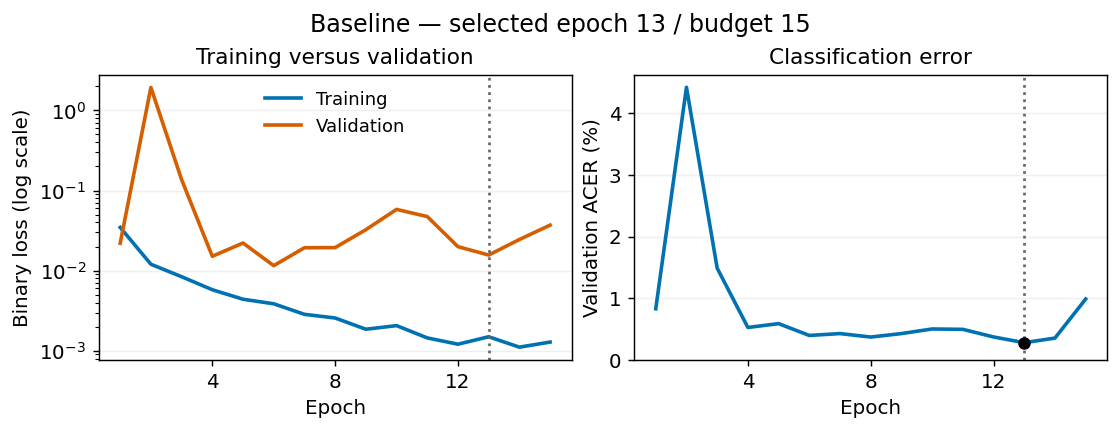

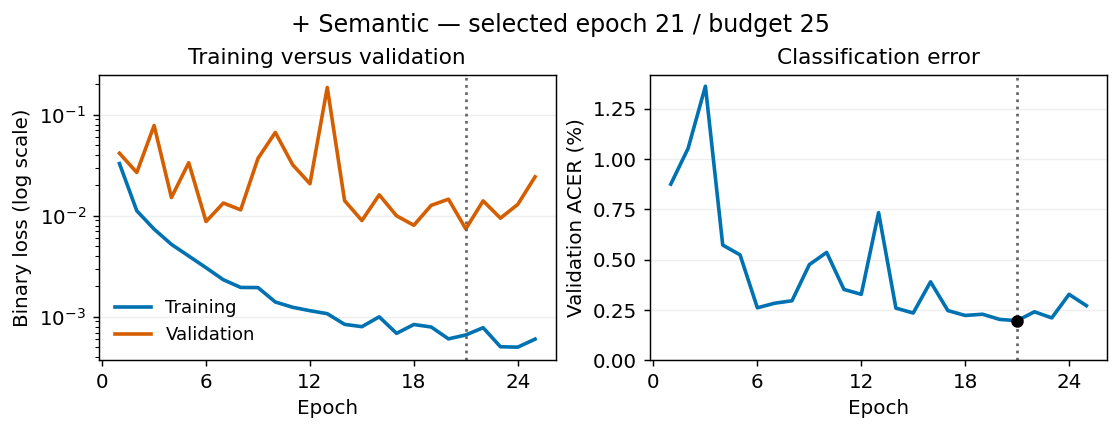

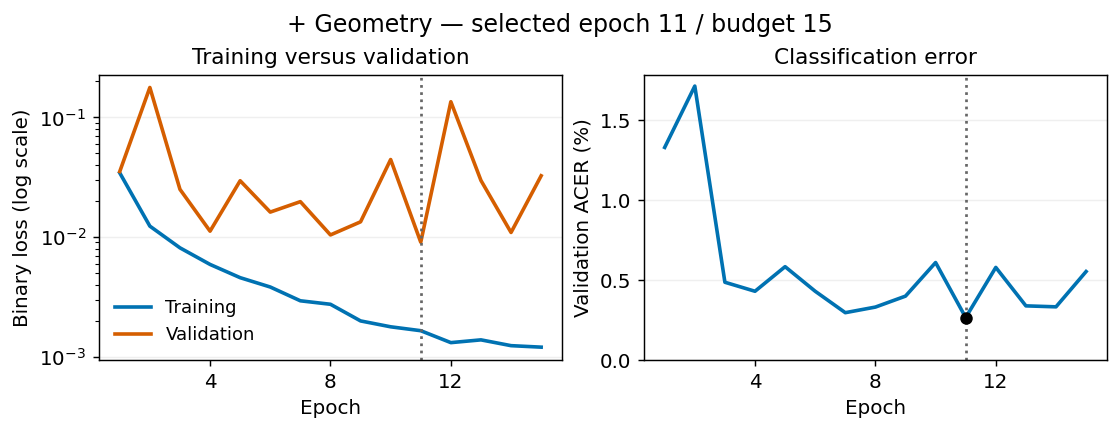

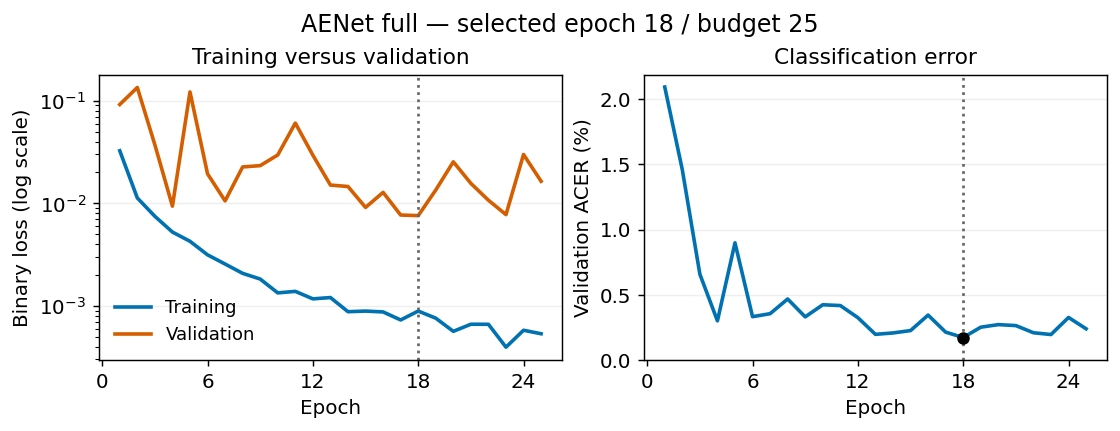

In [ ]:
for arm in VISUAL_ARMS:
    visual_helpers.visual_learning_curves(arm, visual_models[arm])

The binary training losses decrease, while validation BCE and ACER fluctuate. AENet reaches its lowest validation ACER at epoch 18 (0.173%), and binary-semantic at epoch 21 (0.196%); further recorded epochs do not improve those selected minima. The 25-epoch run therefore supplies evidence for checkpoint selection, not proof that every loss has converged. The large early baseline validation BCE spike also shows why training loss alone is insufficient.

In [ ]:
display_table(
    [
        "Configuration",
        "Selected epoch",
        "Total loss: first → last",
        "Selected threshold",
    ],
    [
        [
            VISUAL_SHORT_NAMES[arm],
            visual_models[arm]["result"]["selected_epoch"],
            f"{visual_models[arm]['history'][0]['losses']['total']:.4f} → "
            f"{visual_models[arm]['history'][-1]['losses']['total']:.4f}",
            f"{visual_models[arm]['result']['threshold']:.4f}",
        ]
        for arm in VISUAL_ARMS
    ],
)

Configuration,Selected epoch,Total loss: first → last,Selected threshold
Baseline,13,0.0346 → 0.0013,0.1126
+ Semantic,21,0.2574 → 0.0739,0.5147
+ Geometry,11,0.0450 → 0.0044,0.5738
AENet full,18,0.2688 → 0.0770,0.4648


### 14\.3 Errors after crop review

These matrices evaluate the existing best checkpoints on 49,479 validation images, after the same 25 bad crops are removed for every model. Rows show dataset labels and columns show predictions. The two off-diagonal cells count live images rejected as spoof and spoof images accepted as live. Section 14.5 shows how excluding those crops changes the error rates.

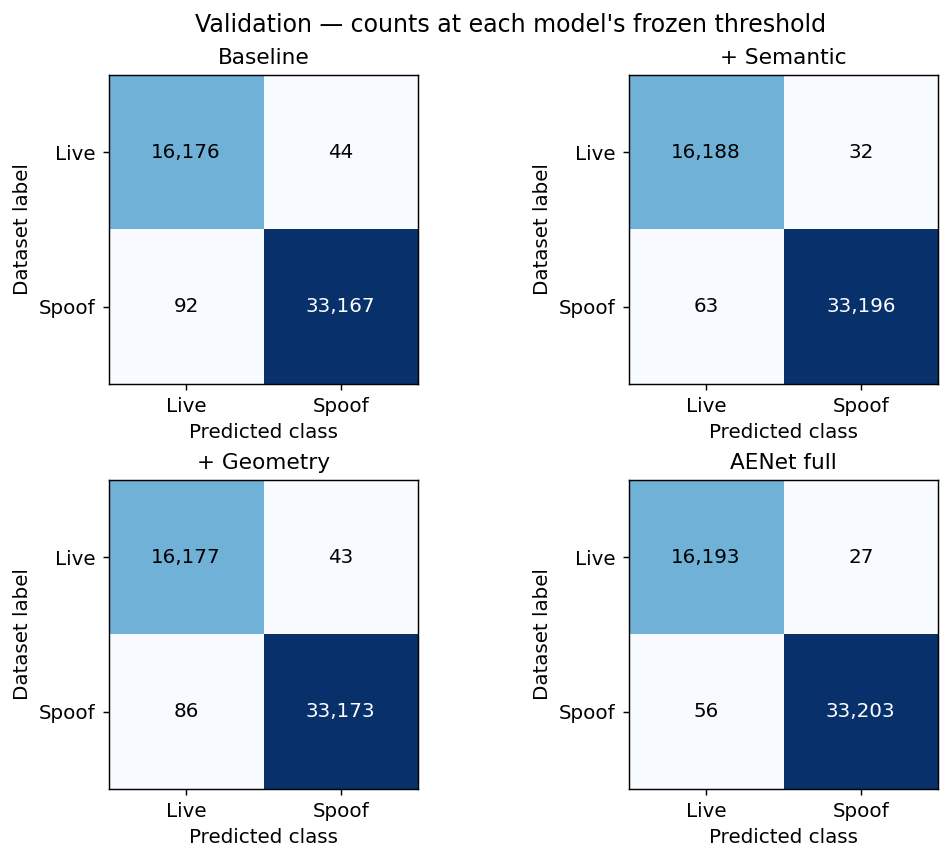

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(8, 6.5), constrained_layout=True)
for arm, ax in zip(VISUAL_ARMS, axes.flat, strict=True):
    model = visual_models[arm]
    visual_helpers.visual_confusion(
        ax,
        model["labels"],
        model["scores"],
        model["result"]["threshold"],
        VISUAL_SHORT_NAMES[arm],
    )
fig.suptitle("Validation — counts at each model's frozen threshold")
plt.show()

AENet full makes 83 errors on the retained validation images; the baseline makes 136. These counts compare predictions with the dataset's live/spoof labels. They do not verify that every remaining label is correct.

#### 14\.3\.1 ROC curves

Each ROC panel contains one model and uses the same zoomed axes. ROC-AUC in the title still uses the full curve. Higher curves are better. The dot is that model's frozen threshold. Here spoof is the positive class, so the horizontal axis is the percentage of live faces rejected as spoof; it is not APCER.

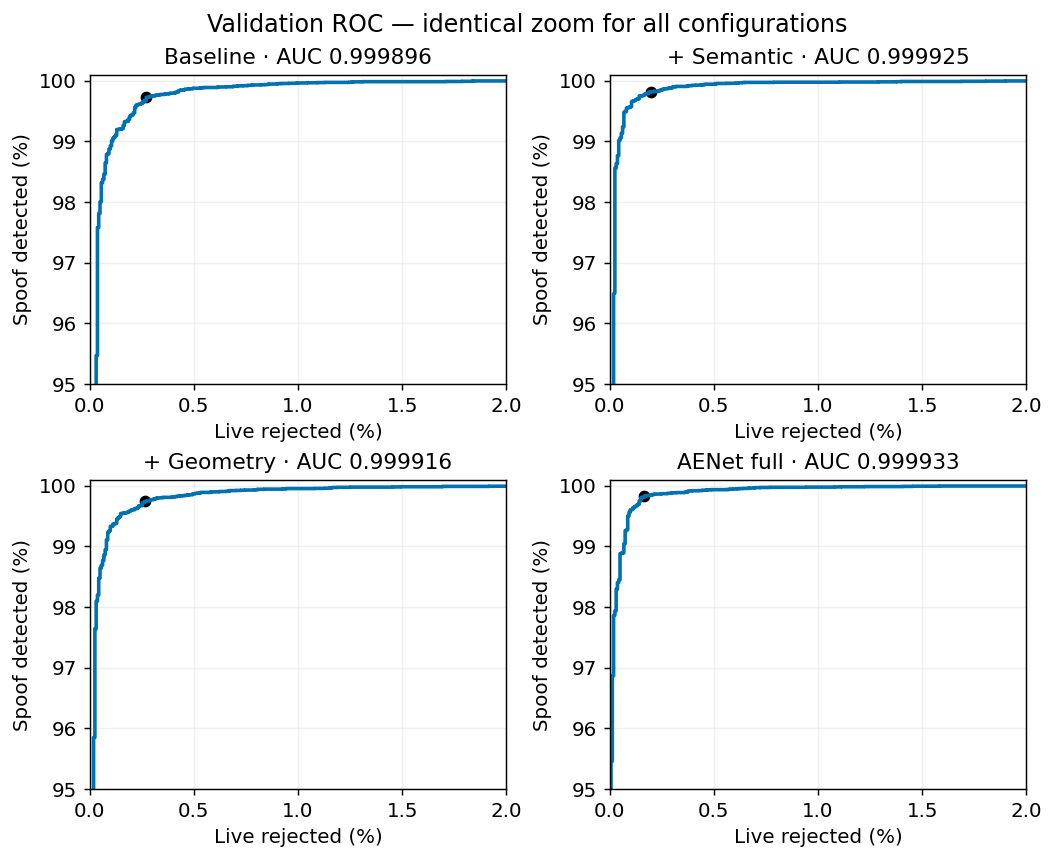

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(8, 6.5), constrained_layout=True)
for arm, ax in zip(VISUAL_ARMS, axes.flat, strict=True):
    model = visual_models[arm]
    fpr, tpr, _ = roc_curve(model["labels"], model["scores"])
    prediction = model["scores"] >= model["result"]["threshold"]
    ax.plot(100 * fpr, 100 * tpr, color=VISUAL_COLORS[0], linewidth=2)
    ax.scatter(
        100 * prediction[model["labels"] == 0].mean(),
        100 * prediction[model["labels"] == 1].mean(),
        color="black",
        s=30,
    )
    ax.set(
        xlim=(0, 2),
        ylim=(95, 100.1),
        xlabel="Live rejected (%)",
        ylabel="Spoof detected (%)",
        title=f"{VISUAL_SHORT_NAMES[arm]} · AUC {roc_auc_score(model['labels'], model['scores']):.6f}",
    )
    ax.grid(alpha=0.2)
fig.suptitle("Validation ROC — identical zoom for all configurations")
plt.show()

The separate panels show the low-error region without overlapping model lines. Their operating thresholds differ; a numerical score from one model is not interchangeable with the same score from another.

### 14\.4 Live and spoof errors

This comparison uses the same 49,479 filtered validation images as section 14.3. Two errors matter at the saved threshold: rejecting a live image (BPCER) and accepting a spoof image (APCER). The following panels show these rates separately for each model. Lower bars are better; each bar also gives the error count and the number of images in that class.

The threshold table identifies the operating point for each model. Scores use different scales across models, so compare error rates rather than raw thresholds. The four-panel figure below compares scores of misclassified images only, without the dominant correct-score peaks.

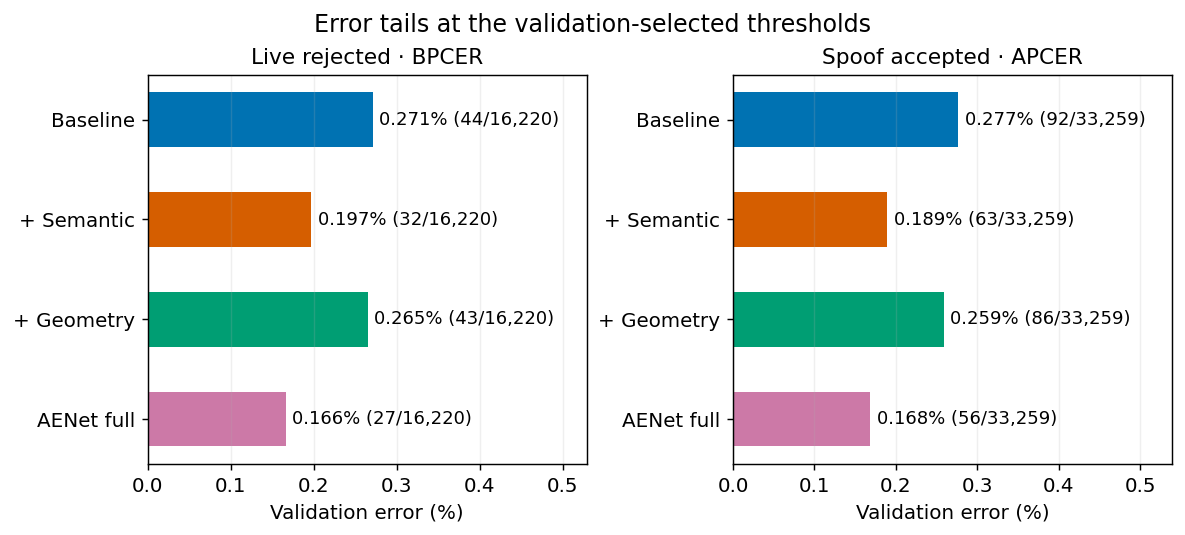

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4), constrained_layout=True)
for ax, label, title in zip(
    axes, (0, 1), ("Live rejected · BPCER", "Spoof accepted · APCER"), strict=True
):
    rates, counts, totals = [], [], []
    for arm in VISUAL_ARMS:
        model = visual_models[arm]
        mask = model["labels"] == label
        total = int(mask.sum())
        errors = int((~model["correct"][mask]).sum())
        rates.append(100 * errors / total)
        counts.append(errors)
        totals.append(total)
    positions = np.arange(len(VISUAL_ARMS))
    ax.barh(positions, rates, height=0.55, color=VISUAL_COLORS)
    for position, rate, count, total in zip(
        positions, rates, counts, totals, strict=True
    ):
        ax.text(
            rate + 0.008,
            position,
            f"{rate:.3f}% ({count}/{total:,})",
            va="center",
            fontsize=10,
        )
    ax.set_yticks(positions, [VISUAL_SHORT_NAMES[arm] for arm in VISUAL_ARMS])
    ax.invert_yaxis()
    ax.set(xlim=(0, max(rates) * 1.95), xlabel="Validation error (%)", title=title)
    ax.grid(axis="x", alpha=0.2)
fig.suptitle("Error tails at the validation-selected thresholds")
plt.show()

The operating thresholds belong to their historical checkpoints. They are reported separately from error rates because score scales differ between models.

In [ ]:
visual_tail_rows = []

for arm in VISUAL_ARMS:
    model = visual_models[arm]
    visual_tail_rows.append(
        [VISUAL_SHORT_NAMES[arm], f"{model['result']['threshold']:.6f}"]
    )
display_table(["Configuration", "Frozen spoof-score threshold"], visual_tail_rows)

Configuration,Frozen spoof-score threshold
Baseline,0.112574
+ Semantic,0.514739
+ Geometry,0.573811
AENet full,0.464838


AENet full rejects 27 of 16,220 live images (0.166%), compared with 44 (0.271%) for the baseline. It accepts 56 of 33,259 spoof images (0.168%), compared with 92 (0.277%) for the baseline. These differences are easier to see in the error bars than in full score histograms. The models have unequal training budgets and were trained before crop review.

Only misclassified images appear below. Blue bars show live images predicted as spoof; orange bars show spoof images predicted as live. The dashed line is each model’s unchanged threshold. Counts near the line are borderline errors; counts near 0 or 1 are errors with extreme scores. Panels use independent image-count axes; compare their tick values, not bar heights alone.

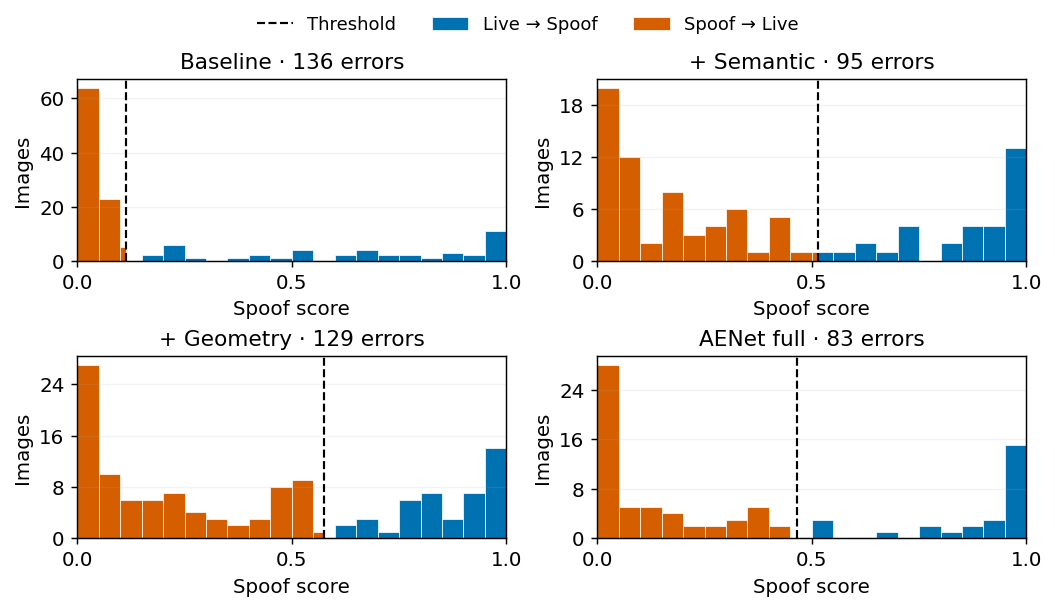

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(8, 4.6), constrained_layout=True)
for arm, ax in zip(VISUAL_ARMS, axes.flat, strict=True):
    model = visual_models[arm]
    visual_helpers.visual_error_scores(
        ax,
        model["labels"],
        model["scores"],
        model["result"]["threshold"],
        VISUAL_SHORT_NAMES[arm],
    )
handles, legend_labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="outside upper center", ncol=3, frameon=False)
plt.show()

### 14\.5 After removing bad crops

These metrics reuse the selected checkpoints' saved predictions on 49,479 retained validation rows. The same 25 confirmed bad crops are removed for every configuration; weights and thresholds remain fixed.

| Configuration | Epoch | Original validation ACER | Filtered validation ACER |
| --- | ---: | ---: | ---: |
| Baseline | 13 | 0.2829% | 0.2739% |
| + Geometry | 11 | 0.2662% | 0.2618% |
| + Semantic | 21 | 0.1962% | 0.1933% |
| AENet full | 18 | 0.1734% | 0.1674% |

AENet full still ranks first. The delivery retains that original checkpoint; no post-review retraining is claimed. The lower rates describe a filtered input population, not improved model weights or removal of prior training exposure. Future training must use the frozen exclusions consistently.

[Saved predictions and metrics](../evidence/liveness/crop-review/filtered-view-v4-20261126/) preserve both populations and their bindings.


## 15\. Public test and camera trials

The public test measures errors on 67,170 face images. The camera trials check how the same model and threshold work on recordings of live faces, still photos on phone screens and photos printed on A4 paper.


The saved public-test results use the original 67,170-row assignment. They have not been recomputed on the 67,129-row filtered test selection. Camera clips are a separate input and are not filtered by dataset row indices.


### 15\.1 Evaluation inputs

The public test uses a verified cache of cropped RGB faces (about 10.1 GB). Colab copies the cache to its temporary disk and checks its SHA-256 checksum before scoring the images. For the camera trials, YuNet finds the faces in the camera footage before the liveness model scores them.


In [ ]:
test_cache = DRIVE_PROJECT / "data/liveness/face-cache/faces/test"
receipt_file = test_cache / "decoded-faces.json"
if receipt_file.is_file():
    test_receipt = json.loads(receipt_file.read_text())
    display_table(
        ["Evaluation input", "Value"],
        [
            ["Public-test images", test_receipt["shape"][0]],
            ["Array", f"{test_receipt['dtype']} {test_receipt['shape']}"],
            ["Cache size", f"{test_receipt['bytes'] / 1e9:.2f} GB"],
            [
                "Original image/box SHA checks",
                test_receipt["verification"]["original_image_and_box_sha256"],
            ],
            [
                "Exact tensor-parity checks",
                test_receipt["verification"]["tensor_parity_rows"],
            ],
        ],
    )
elif ACTION == "evaluate":
    raise FileNotFoundError("Publish the test cache before starting evaluation")
else:
    print("Test cache has not been published yet; inspect mode does not build it.")

Test cache has not been published yet; inspect mode does not build it.


### 15\.2 Run evaluation

In section 3, set `ACTION` to **evaluate** for the public test or **inference** to update the camera results. The two actions can run in either order. Both use the validation-selected checkpoint and save metrics for later inspection.

Before either action runs, Colab checks that the workflow scripts match the versions in the release inventory.


In [ ]:
if ACTION == "evaluate" or (IS_COLAB and ACTION == "inference"):
    evaluation_bootstrap = PROJECT / "evaluation-bootstrap"
    evaluation_bootstrap.mkdir(parents=True, exist_ok=True)
    for name in (
        "liveness_training_health.py",
        "stage_liveness_training_runtime.py",
        "supervise_liveness_training_process.py",
        "run_liveness_public_test.py",
        "liveness_camera_inputs.py",
    ):
        stage_release_script(
            DRIVE_PROJECT, release["files"]["scripts/" + name], evaluation_bootstrap
        )
    if str(evaluation_bootstrap) not in sys.path:
        sys.path.insert(0, str(evaluation_bootstrap))
    evaluation_spec = importlib.util.spec_from_file_location(
        "liveness_evaluation_workflow",
        evaluation_bootstrap / "run_liveness_public_test.py",
    )
    evaluation_module = importlib.util.module_from_spec(evaluation_spec)
    evaluation_spec.loader.exec_module(evaluation_module)

#### 15\.2\.1 Public test inference

Colab first checks whether it can reuse the saved public-test result. If the checkpoint and test inputs still match, it reads that result without copying the face cache or scoring the images again.


In [ ]:
if ACTION == "evaluate":
    evaluation_module.run_notebook(
        DRIVE_PROJECT, PROJECT, CHECKPOINT_RUN, output_root=TRAINING_OUTPUT
    )

#### 15\.2\.2 Camera clip inference

Upload MP4s to the [camera recordings folder](https://drive.google.com/drive/folders/1rlxPso7MjP6I8AKiIHu684sKoR5yyWta). The evaluator reads the subject, time, clip type and lighting from the filename. Use `subject-YYYYMMDD_HHMMSS-type-lighting.mp4`, with live, screen or print for type and bright or dim for lighting.

Local inference uses the existing Python environment and an explicit CPU device. Colab preserves the isolated CUDA route. Both use the same camera scorer and validation-selected checkpoint.


In [ ]:
if ACTION == "inference" and IS_COLAB:
    _, checkpoint, checksum = evaluation_module.selected_checkpoint(CHECKPOINT_RUN)
    camera_folder = DRIVE_PROJECT / "data/liveness/camera-trials"
    if not camera_folder.is_dir():
        raise FileNotFoundError(
            f"Camera folder is not available in the Drive mount: {camera_folder}"
        )

    record = release["evaluation"]["camera_evaluator"]
    batch_script = stage_release_script(DRIVE_PROJECT, record, evaluation_bootstrap)

The camera helper handles source verification, environment preparation and diagnostic logs on Colab. Local inference calls the same prediction workflow through the shared CLI, without installing packages or invoking public-test evaluation. CPU and CUDA prediction caches remain separate.


In [ ]:
if ACTION == "inference":
    if IS_COLAB:
        helper_path = evaluation_bootstrap / "liveness_camera_inputs.py"
        spec = importlib.util.spec_from_file_location(
            "camera_notebook_inputs", helper_path
        )
        camera_helper = importlib.util.module_from_spec(spec)
        spec.loader.exec_module(camera_helper)
        python = camera_helper.run_colab_inference(
            DRIVE_PROJECT,
            PROJECT,
            checkpoint,
            checksum,
            camera_folder,
            TRAINING_OUTPUT,
            release,
            batch_script,
            evaluation_module,
        )
    else:
        subprocess.run(
            [
                sys.executable,
                str(PROJECT / "scripts/run_liveness_notebook.py"),
                "--action",
                "inference",
                "--device",
                "cpu",
                "--input",
                str(PROJECT / "data/liveness/camera-trials"),
                "--run-dir",
                str(CHECKPOINT_RUN),
            ],
            cwd=PROJECT,
            check=True,
        )

### 15\.3 Evaluation results



#### 15\.3\.1 Public test metrics

APCER, BPCER and ACER use the threshold chosen on validation.

ROC-AUC measures how often a spoof image scores higher than a live image across all such pairs, with ties counting as half. Test EER describes a separate threshold where the test error rates are closest. The system still makes decisions at the validation threshold.


In [ ]:
evaluation_index = None
evaluation_root = None
choice_file = CHECKPOINT_RUN / "model-choice.json"

if choice_file.is_file():
    choice = json.loads(choice_file.read_text())
    selected_arm = choice["chosen"]
    selected_sha = choice["arms"][selected_arm]["checkpoint_sha256"]
    evaluation_root = TRAINING_OUTPUT / "evaluation" / selected_arm / selected_sha[:16]
    index_file = evaluation_root / "evaluation-results.json"
    if not index_file.is_file():
        evaluation_root = (
            CHECKPOINT_RUN / "evaluation" / selected_arm / selected_sha[:16]
        )
        index_file = evaluation_root / "evaluation-results.json"
    if index_file.is_file():
        evaluation_index = json.loads(index_file.read_text())
        if evaluation_index["checkpoint_sha256"] != selected_sha:
            raise ValueError("Evaluation checkpoint differs from validation selection")

if evaluation_index is None or "public-test" not in evaluation_index["results"]:
    print(
        "No public-test result for this continuation yet; "
        "saved validation results are still available."
    )

We evaluate the selected checkpoint on the 67,129 test images retained after review. The report reuses the saved per-image scores at the unchanged validation threshold; no test result is used to choose a model or threshold.

In [ ]:
public_result = None
if evaluation_index and "public-test" in evaluation_index["results"]:
    report_name = release["crop_review"]["test_evaluation"]
    public_result = json.loads(
        verified_source(DRIVE_PROJECT, release["files"][report_name])
    )
    if public_result["checkpoint_sha256"] != selected_sha:
        raise ValueError("Filtered test report uses a different checkpoint")
    if (
        public_result["cache_view_sha256"]
        != hashlib.sha256((REVIEWED_VIEW / "cache-view.json").read_bytes()).hexdigest()
    ):
        raise ValueError("Filtered test report uses a different image selection")

In [ ]:
if public_result is not None:
    metrics = public_result["metrics"]
    rows = [["Configuration", selected_arm], ["Images", metrics["samples"]]]
    for metric in ("APCER", "BPCER", "ACER", "ROC_AUC"):
        rows.append([metric, f"{100 * metrics[metric]:.3f}%"])
    benchmark = public_result.get("published_benchmark", {})
    if "nearest_discrete_EER" in benchmark:
        rows.append(
            [
                "Test EER (descriptive)",
                f"{100 * benchmark['nearest_discrete_EER']:.3f}%",
            ]
        )
    display_table(["Public-test metric", "Value"], rows)

Public-test metric,Value
Configuration,aenet-full
Images,67129
APCER,12.222%
BPCER,0.131%
ACER,6.176%
ROC_AUC,99.858%
Test EER (descriptive),1.643%


##### 15\.3\.1\.1 Confusion matrix

The matrix uses the same 67,129 retained test images and frozen validation threshold as the table above. The 41 excluded images are the confirmed crop defects listed in the review; predictions did not determine which images were excluded.

In [ ]:
visual_test_available = public_result is not None
if visual_test_available:
    test_prediction_path = visual_child(
        DRIVE_PROJECT, public_result["filtered_predictions"]
    )
    if (
        hashlib.sha256(test_prediction_path.read_bytes()).hexdigest()
        != public_result["filtered_predictions_sha256"]
    ):
        raise ValueError("Filtered test predictions changed")
    test_rows, test_labels, test_scores = visual_predictions(test_prediction_path)
    if {row["split"] for row in test_rows} != {"test"}:
        raise ValueError("Public-test predictions contain another split")
    if len(test_rows) != public_result["metrics"]["samples"]:
        raise ValueError("Filtered test coverage differs from the report")
    test_threshold = choice["arms"][selected_arm]["threshold"]
    if test_threshold != public_result["metrics"]["threshold"]:
        raise ValueError("Test threshold differs from validation selection")

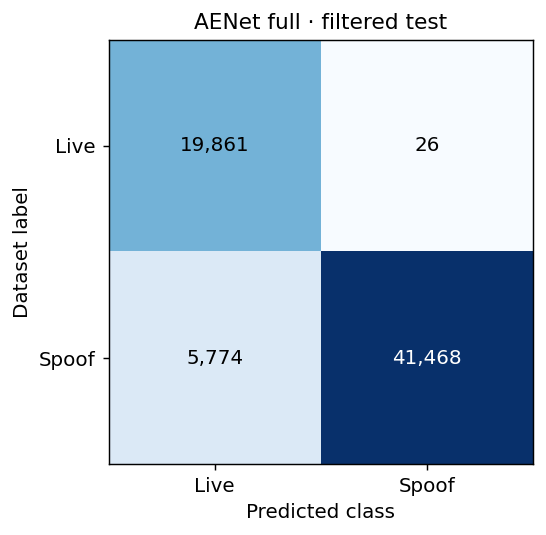

In [ ]:
if visual_test_available:
    fig, ax = plt.subplots(figsize=(4.8, 4), constrained_layout=True)
    visual_helpers.visual_confusion(
        ax, test_labels, test_scores, test_threshold, "AENet full · filtered test"
    )
    plt.show()
else:
    print("No filtered test report for the selected checkpoint.")

On the retained test images, AENet accepts 5,774 spoof images as live (APCER 12.222%) and rejects 26 live images (BPCER 0.131%). ACER is 6.176%. This remains a large gap from validation despite ROC-AUC of 0.9986. The result describes the filtered project subset, not the complete CelebA-Spoof test benchmark.

##### 15\.3\.1\.2 ROC curve

ROC-AUC summarizes ranking over possible thresholds. It can remain high even when the validation threshold accepts many test attacks. The marked point uses the original frozen threshold; the curve does not choose a replacement.

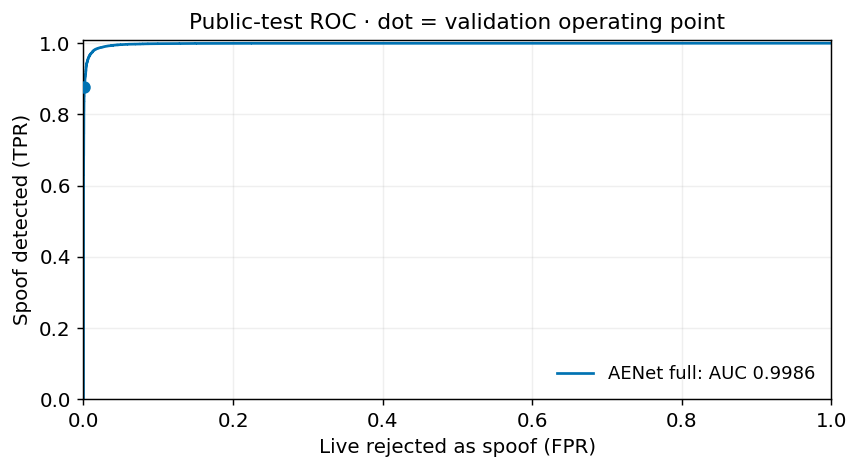

In [ ]:
if visual_test_available:
    fig, ax = plt.subplots(figsize=(6.5, 3.5), constrained_layout=True)
    visual_helpers.visual_roc(
        ax, test_labels, test_scores, test_threshold, "AENet full", VISUAL_COLORS[0]
    )
    ax.set_title("Public-test ROC · dot = validation operating point")
    ax.legend(frameon=False, loc="lower right")
    plt.show()

##### 15\.3\.1\.3 Score distribution

Spoof scores below the dashed line are attacks accepted as live. The two distributions are normalized within their true classes, matching the validation figures.

The test errors are shown in two panels: 26 live images rejected as spoof on the left and 5,774 spoof images accepted as live on the right. Each panel has its own image-count scale so both distributions remain visible.

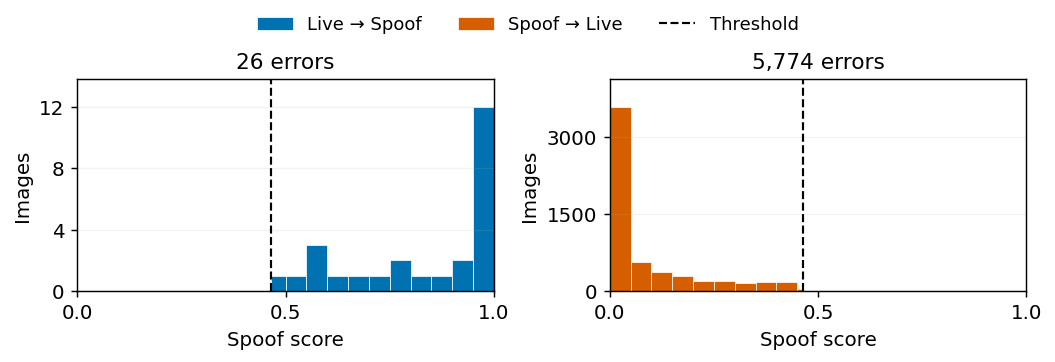

In [ ]:
if visual_test_available:
    visual_helpers.visual_test_error_scores(test_labels, test_scores, test_threshold)
    plt.show()

#### 15\.3\.2 Camera trial results

Each row shows one clip. The table groups clips by subject and lists each subject’s recordings in capture order. Row ID numbers the rows in that order. **Decision** shows whether the model classified it as live or spoof. **Outcome** shows whether that decision matched the clip’s label. If no frame can be scored, the result is **Uncertain**.

When reviewing a decision, compare **Median spoof score** with **Decision threshold**, listed in the camera results summary. The score is the median across the clip’s scored frames. A clip close to the threshold is worth reviewing because a small change in its score could switch the decision between live and spoof.


In [ ]:
trial_result = None
result_path = None
if choice_file.is_file():
    camera_file = TRAINING_OUTPUT / "camera-evaluation" / selected_sha / "latest.json"
    if not camera_file.is_file():
        camera_file = (
            CHECKPOINT_RUN / "camera-evaluation" / selected_sha / "latest.json"
        )
    if camera_file.is_file():
        result_path = camera_file

if result_path is not None:
    trial_result = json.loads(result_path.read_text())
    if trial_result["checkpoint_sha256"] != selected_sha:
        raise ValueError("Trial result checkpoint differs from validation selection")

Summarize the saved camera report and identify the checkpoint and threshold used for the displayed results.

In [ ]:
if trial_result is None:
    print("No trial results for the selected action and checkpoint.")
else:
    selected_result = choice["arms"][selected_arm]
    rows = [
        [
            "Configuration / epoch",
            f"{selected_arm} / {selected_result['selected_epoch']}",
        ],
        ["Checkpoint SHA-256", trial_result["checkpoint_sha256"]],
        ["Decision threshold", trial_result["threshold"]],
        ["Recordings", len(trial_result["trials"])],
        ["Inference device", trial_result.get("bindings", {}).get("device", "cuda")],
        [
            "PyTorch build",
            trial_result.get("bindings", {}).get("torch", "Not recorded"),
        ],
    ]
    rows.extend(
        [
            ["Evaluated in camera run", trial_result["inferred"]],
            ["Reused in camera run", trial_result["reused"]],
        ]
    )
    display_table(["Camera evaluation", "Value"], rows)

Camera evaluation,Value
Configuration / epoch,aenet-full / 18
Checkpoint SHA-256,6715d53461e6d123d34ca714c7b24b8b66a726949889bcf4f72955fceb1aa430
Decision threshold,0.46483826637268066
Recordings,25
Inference device,cuda
PyTorch build,2.13.0+cu130
Evaluated in camera run,0
Reused in camera run,25


Arrange the saved recording identifiers and frame decisions into rows for the camera results table.

In [ ]:
trial_rows = []
if trial_result is not None:
    for trial in trial_result["trials"]:
        name, captured, kind, lighting = trial["trial_id"].rsplit("-", 3)
        capture_time = datetime.strptime(captured, "%Y%m%d_%H%M%S")
        if kind not in ("live", "screen", "print") or kind != trial["kind"]:
            raise ValueError(f"Invalid presentation type for {trial['trial_id']}")

        expected = "live" if kind == "live" else "spoof"
        decision = trial["status"]
        if decision == "uncertain":
            outcome = "Uncertain"
        else:
            outcome = "Correct" if decision == expected else "Incorrect"
        score = trial["median_spoof_score"]
        trial_rows.append(
            [
                name,
                capture_time.strftime("%Y-%m-%d"),
                capture_time.strftime("%H:%M:%S"),
                kind,
                lighting,
                "unavailable" if score is None else f"{score:.6f}",
                decision,
                outcome,
            ]
        )
    trial_rows.sort(key=lambda row: (row[0].casefold(), row[1], row[2]))

Display the per-recording decisions for the selected checkpoint with subject, capture time, presentation type and lighting.

In [ ]:
if trial_result is not None:
    display_table(
        [
            "Row ID",
            "Subject",
            "Capture date",
            "Capture time",
            "Type",
            "Brightness",
            "Median spoof score",
            "Decision",
            "Outcome",
        ],
        [[row_id, *row] for row_id, row in enumerate(trial_rows, start=1)],
    )

Row ID,Subject,Capture date,Capture time,Type,Brightness,Median spoof score,Decision,Outcome
1,An,2026-11-24,11:25:27,print,bright,0.999988,spoof,Correct
2,An,2026-11-24,11:30:10,print,dim,0.999967,spoof,Correct
3,Dung,2026-11-23,05:22:14,live,bright,0.000174,live,Correct
4,Dung,2026-11-23,05:22:45,live,dim,0.040086,live,Correct
5,Dung,2026-11-23,05:23:22,screen,bright,1.000000,spoof,Correct
6,Dung,2026-11-23,05:24:07,screen,dim,0.991217,spoof,Correct
7,Dung,2026-11-23,05:26:07,live,bright,0.002886,live,Correct
8,Dung,2026-11-24,11:23:25,print,bright,0.999767,spoof,Correct
9,Dung,2026-11-24,11:29:21,print,dim,0.999997,spoof,Correct
10,LeDucHoangVy,2026-11-23,12:06:01,live,bright,0.000970,live,Correct


The camera table reflects the most recent saved run. Select inference mode to update it after uploading new clips. The full set includes live faces, still photos on phone screens and A4 prints under bright and dim lighting. [Camera recordings on Drive](https://drive.google.com/drive/folders/1rlxPso7MjP6I8AKiIHu684sKoR5yyWta)



## 16\. Model errors

This evaluates the existing best checkpoints on filtered validation images. The following comparison asks which baseline errors AENet corrects and which new errors it makes. All models are scored on the same 49,479 retained validation images. Here, correct and wrong mean agreement or disagreement with the dataset label.

The gallery excludes quarantined images. Its predictions still come from checkpoints trained before crop review; filtering evaluation images does not change those weights.

In [ ]:
visual_baseline = visual_models["binary-classification"]["correct"]
visual_groups = (
    ("Baseline disagrees / variant matches label", lambda a, b: ~a & b),
    ("Baseline matches / variant disagrees with label", lambda a, b: a & ~b),
    ("Both disagree with label", lambda a, b: ~a & ~b),
    ("Both match label", lambda a, b: a & b),
)
paired_rows = []
for arm in VISUAL_ARMS[1:]:
    correct = visual_models[arm]["correct"]
    paired_rows.append(
        [
            VISUAL_SHORT_NAMES[arm],
            *[int(mask(visual_baseline, correct).sum()) for _, mask in visual_groups],
        ]
    )
display_table(
    [
        "Configuration",
        "Gained agreement",
        "Lost agreement",
        "Both disagree",
        "Both agree",
    ],
    paired_rows,
)

Configuration,Gained agreement,Lost agreement,Both disagree,Both agree
+ Semantic,92,51,44,49292
+ Geometry,57,50,79,49293
AENet full,88,35,48,49308


AENet full corrects 88 baseline errors but makes 35 new errors, leaving 83 errors versus the baseline's 136. + Semantic corrects 92 and introduces 51; + Geometry corrects 57 and introduces 50. These are image counts. ACER instead gives equal weight to the live and spoof error rates.

### 16\.1 Errors by source type

Each row is one source type. The four dots show error rates under the four frozen thresholds; lower is better. For live faces this is BPCER, and for spoof types it is APCER. Sample counts remain in the row labels. The rows are separated vertically so labels and model differences do not compete with a cluster of bars.

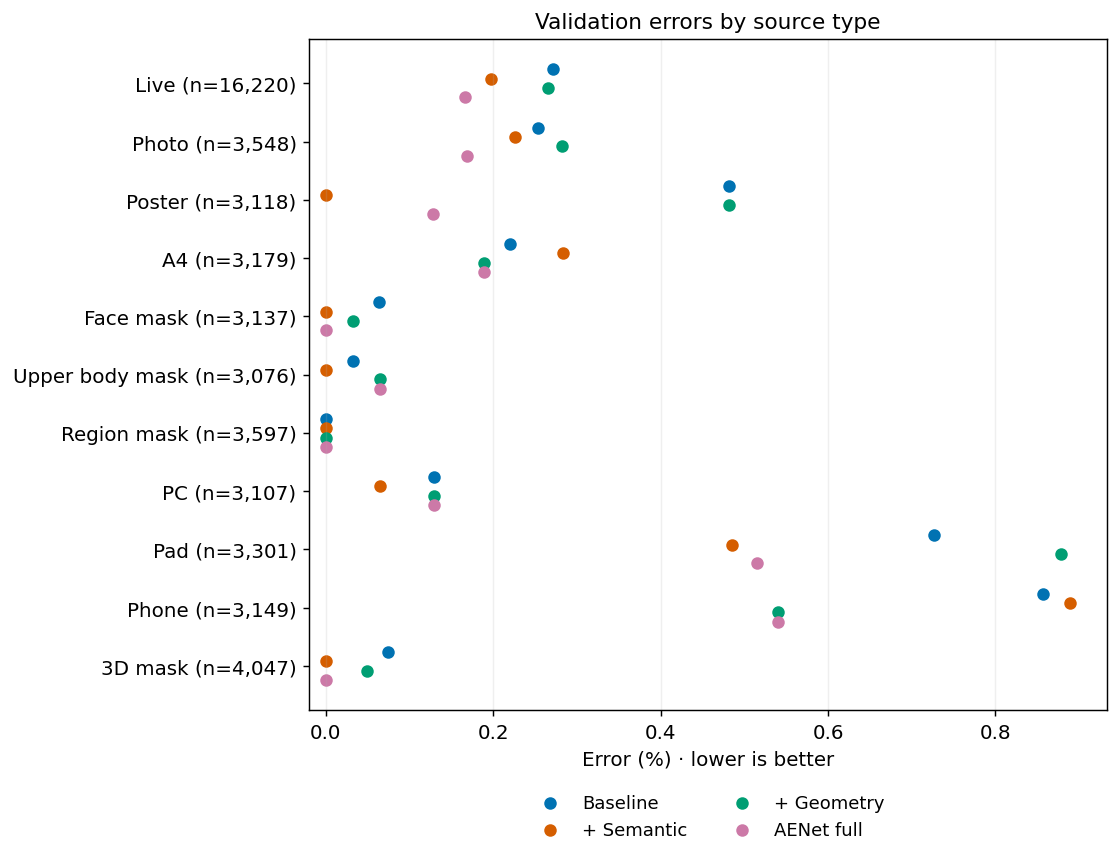

In [ ]:
attack_types = sorted({int(row["source_type"]) for row in visual_reference})
fig, ax = plt.subplots(figsize=(8.5, 6.5), constrained_layout=True)
y_positions = np.arange(len(attack_types))
for offset, (arm, color) in enumerate(zip(VISUAL_ARMS, VISUAL_COLORS, strict=True)):
    model = visual_models[arm]
    rates = []
    for attack in attack_types:
        mask = np.array([int(row["source_type"]) == attack for row in model["rows"]])
        rates.append(100 * (~model["correct"][mask]).mean())
    ax.scatter(
        rates,
        y_positions + (offset - 1.5) * 0.16,
        s=35,
        color=color,
        label=VISUAL_SHORT_NAMES[arm],
    )
counts = [
    sum(int(row["source_type"]) == attack for row in visual_reference)
    for attack in attack_types
]
ax.set_yticks(
    y_positions,
    [
        f"{VISUAL_SOURCE_TYPES[attack]} (n={count:,})"
        for attack, count in zip(attack_types, counts, strict=True)
    ],
)
ax.invert_yaxis()
ax.set(
    xlim=(-0.02, None),
    xlabel="Error (%) · lower is better",
    title="Validation errors by source type",
)
ax.grid(axis="x", alpha=0.2)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False)
plt.show()

### 16\.2 Example predictions

The gallery shows six cases: one live and one spoof image where AENet full corrects the baseline, where it introduces an error, and where both models are wrong. A fixed ordering of image-path hashes selects each example reproducibly. The images illustrate behavior; the counts above show how often it occurs.

Each image has a four-model prediction table. Blue means agreement with the dataset label; orange means disagreement. Spoof scores and thresholds occupy separate columns because a score only becomes a decision when compared with that model's threshold.

The semantic predictions and geometric maps show what the auxiliary heads produce for the same image. They can help interpret a case, but do not prove which training target caused the binary decision.

In [ ]:
# Hash ordering makes example selection repeatable without choosing visually favorable cases.
visual_cases = {}
for arm in VISUAL_ARMS[1:]:
    examples = []
    for group, mask_fn in visual_groups[:3]:
        mask = mask_fn(visual_baseline, visual_models[arm]["correct"])
        for label in (0, 1):
            candidates = np.flatnonzero(mask & (visual_models[arm]["labels"] == label))
            if len(candidates):
                index = min(
                    candidates,
                    key=lambda i: hashlib.sha256(
                        visual_reference[i]["relative_path"].encode()
                    ).hexdigest(),
                )
                examples.append((group, int(index)))
    visual_cases[arm] = examples

visual_example_indices = sorted(
    {index for cases in visual_cases.values() for _, index in cases}
)
visual_raw_root = DRIVE_PROJECT / "data/raw/liveness/celeba-spoof-full"

visual_gallery_cases = visual_cases["aenet-full"]
visual_gallery_indices = [index for _, index in visual_gallery_cases]
with (REVIEWED_VIEW / "quarantine.csv").open(newline="") as stream:
    excluded_examples = {r["relative_path"] for r in csv.DictReader(stream)}
if {
    visual_reference[i]["relative_path"] for i in visual_example_indices
} & excluded_examples:
    raise ValueError("A quarantined input reached the active example gallery")

The following cells load and validate the saved auxiliary report so the gallery can reuse its verified source crops. They perform no inference with the default configuration. Reproduction details follow the example analysis in section 16.3.
Default inspect checks the saved report checksum and its bindings without opening raw images. Set `VERIFY_SOURCE_CROPS = True` to repeat original-image and bounding-box checks; this optional check requires the source dataset.


In [ ]:
visual_inventory = {
    "selection": "Best available validation-selected checkpoints; unequal 15/25-epoch budgets; SHA-256 path ordering within paired live/spoof error groups",
    "examples": [visual_reference[i]["relative_path"] for i in visual_example_indices],
    "models": {},
}
for arm in VISUAL_ARMS:
    model = visual_models[arm]
    receipt = model["receipt"]
    archive = model["archive"]
    visual_inventory["models"][arm] = {
        "checkpoint": f"evidence/liveness/{archive.parent.name}/{archive.name}/{receipt['checkpoint']}",
        "training_sha256": receipt["sha256"],
        "inference_sha256": model["result"]["checkpoint_sha256"],
        "model_version": receipt["inference_metadata"]["model_version"],
        "epoch": model["result"]["selected_epoch"],
        "threshold": model["result"]["threshold"],
        "scores": {
            visual_reference[i]["relative_path"]: float(model["scores"][i])
            for i in visual_example_indices
        },
    }
visual_inventory["cache_view"] = release["crop_review"]["cache_view"]
visual_inventory["reviewed_cache_view_sha256"] = hashlib.sha256(
    (REVIEWED_VIEW / "cache-view.json").read_bytes()
).hexdigest()

Optional regeneration runs verified source in the prepared GPU environment and uses a new timestamped output folder to preserve earlier reports.

In [ ]:
visual_report_root = OUTPUT_PROJECT / "evidence/liveness/visual-analysis-filtered"
if RUN_AUXILIARY_ANALYSIS:
    if ACTION != "inference" or "python" not in globals():
        raise RuntimeError(
            "Prepare the inference GPU environment before auxiliary inference"
        )
    visual_report_root = visual_report_root / datetime.now(UTC).strftime(
        "%Y%m%dT%H%M%SZ"
    )
    visual_report_root.mkdir(parents=True, exist_ok=False)
    inventory_path = visual_report_root / "selected-examples-input.json"
    inventory_path.write_text(json.dumps(visual_inventory, indent=2) + "\n")
    # Verify the helper and its project modules before executing Drive source.
    for name, record in release["files"].items():
        if (
            name.startswith("src/")
            or name == "scripts/audit/inspect_liveness_examples.py"
        ):
            verified_source(DRIVE_PROJECT, record)
    auxiliary_script = DRIVE_PROJECT / "scripts/audit/inspect_liveness_examples.py"
    subprocess.run(
        [
            str(python),
            str(auxiliary_script),
            "--project",
            str(DRIVE_PROJECT),
            "--inventory",
            str(inventory_path),
            "--output",
            str(visual_report_root / "selected-examples.json"),
        ],
        check=True,
    )

The saved report is accepted only when its example identities, checkpoint provenance and illustrated binary decisions match the archived comparison.

In [ ]:
visual_report_path = visual_report_root / "selected-examples.json"
visual_auxiliary = None
if visual_report_path.is_file():
    if not RUN_AUXILIARY_ANALYSIS and not VERIFY_SOURCE_CROPS:
        report_name = (
            "evidence/liveness/visual-analysis-filtered/selected-examples.json"
        )
        expected = release["files"][report_name]["sha256"]
        if hashlib.sha256(visual_report_path.read_bytes()).hexdigest() != expected:
            raise ValueError(
                "Saved auxiliary report changed; verify its raw sources or regenerate it"
            )
    visual_auxiliary = visual_read_json(visual_report_path)
    if (
        visual_auxiliary.get("reviewed_cache_view_sha256")
        != visual_inventory["reviewed_cache_view_sha256"]
    ):
        raise ValueError("Auxiliary examples use another validation split assignment")
    if (
        visual_auxiliary["schema"] != "liveness-selected-examples-v1"
        or visual_auxiliary["split"] != "validation"
        or set(visual_auxiliary["examples"]) != set(visual_inventory["examples"])
    ):
        raise ValueError("Auxiliary report belongs to another example selection")

else:
    print(
        "Saved auxiliary report unavailable. Regenerate it to display source crops and auxiliary outputs."
    )

Source inventory, annotation and illustrated label bindings are checked independently from checkpoint provenance.

In [ ]:
if visual_auxiliary is not None:
    reference_meta = visual_models["aenet-full"]["receipt"]["inference_metadata"]
    if (
        visual_auxiliary["annotations_sha256"]
        != reference_meta["data"]["validation"]["annotations_sha256"]
        or visual_auxiliary["inventory_sha256"]
        != reference_meta["data"]["inventory_sha256"]
    ):
        raise ValueError("Auxiliary report uses another source data release")
    for index in visual_example_indices:
        name = visual_reference[index]["relative_path"]
        example = visual_auxiliary["examples"][name]
        if example["true_binary"] != int(
            visual_reference[index]["binary_label"]
        ) or example["true_source_type"] != int(visual_reference[index]["source_type"]):
            raise ValueError("Auxiliary report labels differ from archived predictions")

Checkpoint hashes, epochs, thresholds and illustrated decisions must match the archived comparison before auxiliary predictions are displayed.

In [ ]:
# Reject stale illustrated decisions even when both reports have the same example names.
if visual_auxiliary is not None:
    for arm, expected in visual_inventory["models"].items():
        observed = visual_auxiliary["models"][arm]
        for field in (
            "training_sha256",
            "inference_sha256",
            "epoch",
            "threshold",
            "model_version",
        ):
            if observed[field] != expected[field]:
                raise ValueError("Auxiliary report checkpoint differs: " + arm)
        for name, score in expected["scores"].items():
            observed_score = visual_auxiliary["examples"][name]["models"][arm][
                "spoof_score"
            ]
            if (observed_score >= expected["threshold"]) != (
                score >= expected["threshold"]
            ):
                raise ValueError(
                    "Auxiliary replay changed an illustrated binary decision"
                )

In [ ]:
if visual_auxiliary is not None:
    print(
        "Auxiliary report:",
        visual_auxiliary["generated_at"],
        visual_auxiliary["device"],
        visual_auxiliary["precision"],
    )

Auxiliary report: 2026-11-26T09:53:36.349695+00:00 NVIDIA GeForce RTX 3050 6GB Laptop GPU float32


The supplied box is reconstructed independently with the source client’s integer-conversion order and clipping. This checks pixel provenance, not semantic validity.

In [ ]:
def visual_supplied_crop(original, box_path, name):
    values = box_path.read_text().splitlines()[0].strip().split(" ")
    if len(values) != 5:
        raise ValueError("This diagnostic requires a parseable supplied box: " + name)
    x, y, width, height = [int(float(v)) for v in values[:4]]
    # Reconstruct the source client's integer conversion and clipping
    # independently, rather than trusting the saved crop's appearance.
    x, y = int(x * (original.width / 224)), int(y * (original.height / 224))
    width = int(width * (original.width / 224))
    height = int(height * (original.height / 224))
    left, top = max(0, x), max(0, y)
    right = original.width if left + width > original.width else x + width
    bottom = original.height if top + height > original.height else y + height
    crop = original.crop((left, top, right, bottom))
    return crop, (left, top, right - left, bottom - top)

In [ ]:
visual_crop_checks = []
if visual_auxiliary is not None and VERIFY_SOURCE_CROPS:
    inventory_record = release["files"][
        "data/raw/liveness/celeba-spoof-full/audits/current-schema-2026-11-12/inventory.csv"
    ]
    inventory_path = DRIVE_PROJECT / inventory_record["delivery_path"]
    with inventory_path.open("rb") as stream:
        if (
            hashlib.file_digest(stream, "sha256").hexdigest()
            != inventory_record["sha256"]
        ):
            raise ValueError("Source crop review inventory changed")
    with inventory_path.open(encoding="utf-8", newline="") as stream:
        review_records = {
            row["relative_path"]: row
            for row in csv.DictReader(stream)
            if row["relative_path"] in visual_auxiliary["examples"]
        }

Each illustrated source image and box must match the inventory. The reconstructed bilinear crop must then match the saved report pixel for pixel.

In [ ]:
if visual_auxiliary is not None and VERIFY_SOURCE_CROPS:
    for name, record in visual_auxiliary["examples"].items():
        image_path = visual_child(visual_raw_root, name)
        box_path = image_path.with_name(image_path.stem + "_BB.txt")
        for file, field in ((image_path, "sha256"), (box_path, "bbox_sha256")):
            with file.open("rb") as stream:
                if (
                    hashlib.file_digest(stream, "sha256").hexdigest()
                    != review_records[name][field]
                ):
                    raise ValueError("Source image or supplied box changed: " + name)
        with Image.open(image_path) as image:
            original = image.convert("RGB")
        crop, rectangle = visual_supplied_crop(original, box_path, name)
        resized = crop.resize((224, 224), Image.Resampling.BILINEAR)
        saved = Image.open(io.BytesIO(base64.b64decode(record["crop_png"]))).convert(
            "RGB"
        )
        if not np.array_equal(np.asarray(resized), np.asarray(saved)):
            raise ValueError("Recorded crop differs from source preprocessing: " + name)
        visual_crop_checks.append(
            [name, f"{crop.width} × {crop.height}", "Exact pixel match"]
        )
    print(
        f"Verified source/box hashes and exact resized-crop pixels: {len(visual_crop_checks)}/{len(visual_auxiliary['examples'])} examples."
    )
else:
    print(
        "Inspect uses saved crop evidence. Set VERIFY_SOURCE_CROPS = True to repeat raw-source pixel checks."
    )

Inspect uses saved crop evidence. Set VERIFY_SOURCE_CROPS = True to repeat raw-source pixel checks.


**Semantic table.**

Each numbered card refers to the same example in the prediction card. It compares + Semantic with AENet full on source type, illumination and their three highest face-attribute scores. Annotation values are shown alongside predictions, so a plausible attribute is not automatically treated as correct. Face attributes use a display threshold of 0.5; this does not change the binary decision threshold.

Names follow the [author's source-type and illumination table](https://github.com/ZhangYuanhan-AI/CelebA-Spoof#annotation-detail) and the [original CelebA attribute order](https://github.com/tensorflow/datasets/blob/master/tensorflow_datasets/datasets/celeb_a/celeb_a_dataset_builder.py). On spoof images the true face-attribute vector is all zero. Auxiliary outputs describe what the heads predict; they do not prove why the binary decision changed.

**Geometric maps.**

Each figure uses the same example numbers. The upper row shows depth and the lower row shows reflection. Columns compare the teacher pseudo-target, + Geometry and AENet full. Depth uses a fixed 0–1 colour scale; reflection is RGB. All maps contain only 14 × 14 pixels. The reference is a teacher-derived training target, not measured physical ground truth.

A black reference reflection on a live image is expected because that target is zero. A spoof image has a zero depth target. Agreement with these targets describes the auxiliary task; it is not proof of causal improvement in live/spoof classification.

In [ ]:
visual_images = {}
if visual_auxiliary is not None:
    for index in visual_gallery_indices:
        name = visual_reference[index]["relative_path"]
        record = visual_auxiliary["examples"][name]
        with Image.open(io.BytesIO(base64.b64decode(record["crop_png"]))) as image:
            visual_images[index] = image.convert("RGB")

Each example card uses the same verified crop and archived model scores. Rendering is delegated to the shared helper; the example selection remains visible above.

In [ ]:
def visual_example_decisions(number, group, index):
    visual_helpers.visual_example_decisions(
        number, group, index, visual_reference, visual_models, visual_images
    )

In [ ]:
def visual_example_semantics(number, index):
    if visual_auxiliary is None:
        return
    name = visual_reference[index]["relative_path"]
    rows = visual_helpers.visual_semantic_rows(visual_auxiliary["examples"][name])
    display(HTML(f"<p><strong>Example {number}</strong> · {escape(name)}</p>"))
    display_table(["Model", "Target", "Prediction", "Annotation"], rows)

In [ ]:
def visual_example_geometry(number, index):
    if visual_auxiliary is not None:
        name = visual_reference[index]["relative_path"]
        visual_helpers.visual_example_geometry(
            number, visual_auxiliary["examples"][name]
        )

#### 16\.2\.1 Example 1: Live

AENet full matches the recorded live label where the baseline predicts spoof.

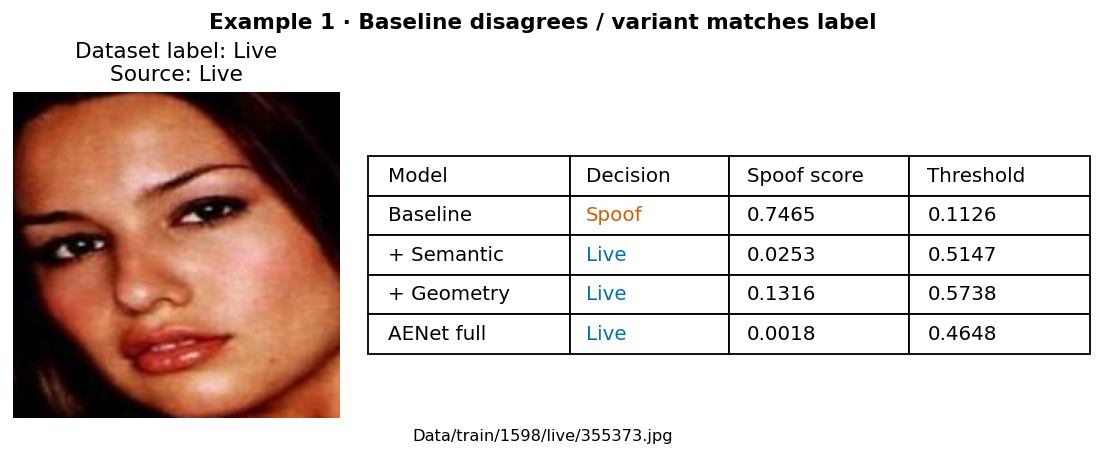

Example 1 · Data/train/1598/live/355373.jpg

Model,Target,Prediction,Annotation
+ Semantic,Source type,Live,Live
+ Semantic,Illumination,Live,Live
+ Semantic,No Beard,Present (0.982),Present
+ Semantic,Wearing Lipstick,Present (0.970),Present
+ Semantic,Heavy Makeup,Present (0.956),Present
AENet full,Source type,Live,Live
AENet full,Illumination,Live,Live
AENet full,No Beard,Present (0.990),Present
AENet full,Wearing Lipstick,Present (0.982),Present
AENet full,Heavy Makeup,Present (0.974),Present


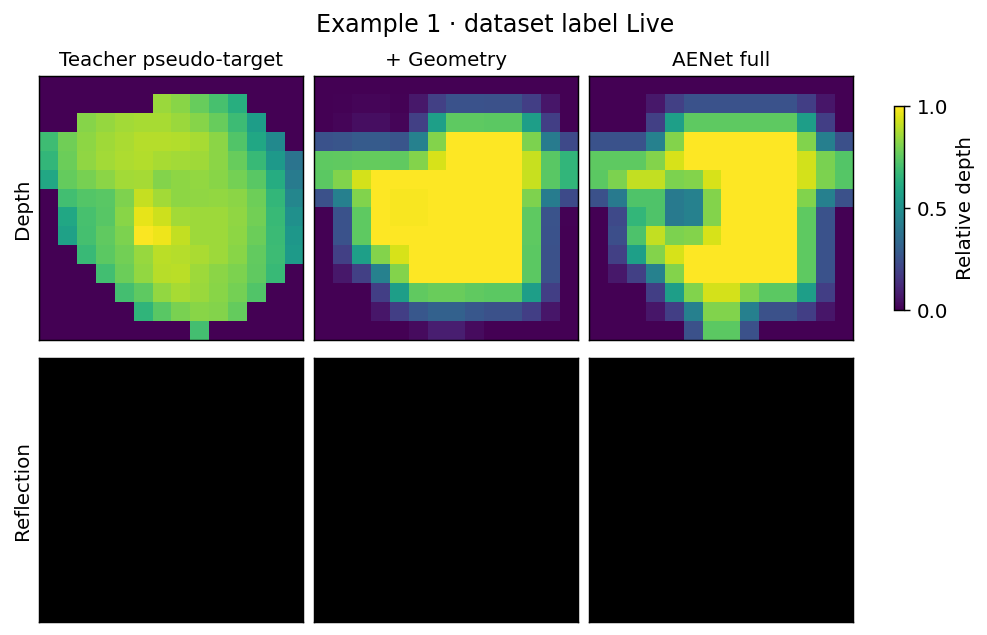

In [ ]:
if visual_auxiliary is not None and len(visual_gallery_cases) > 0:
    example_group, example_index = visual_gallery_cases[0]
    visual_example_decisions(1, example_group, example_index)
    visual_example_semantics(1, example_index)
    visual_example_geometry(1, example_index)
else:
    print("Example 1 unavailable for this report.")

#### 16\.2\.2 Example 2: Spoof

AENet full matches the recorded spoof label where the baseline predicts live.

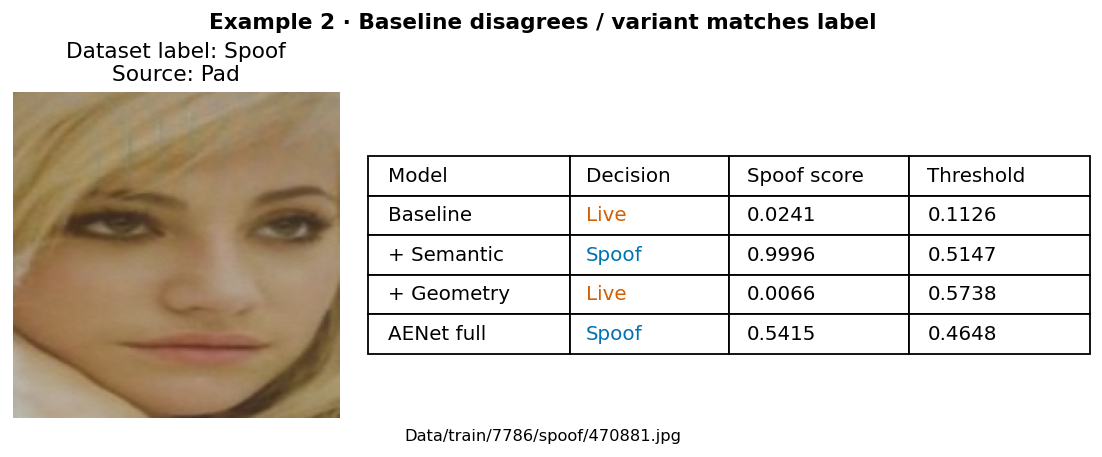

Example 2 · Data/train/7786/spoof/470881.jpg

Model,Target,Prediction,Annotation
+ Semantic,Source type,Poster,Pad
+ Semantic,Illumination,Normal,Back
+ Semantic,Blond Hair,Absent (0.041),Absent
+ Semantic,Young,Absent (0.039),Absent
+ Semantic,No Beard,Absent (0.038),Absent
AENet full,Source type,Upper body mask,Pad
AENet full,Illumination,Live,Back
AENet full,No Beard,Present (0.754),Absent
AENet full,Blond Hair,Present (0.581),Absent
AENet full,Young,Absent (0.372),Absent


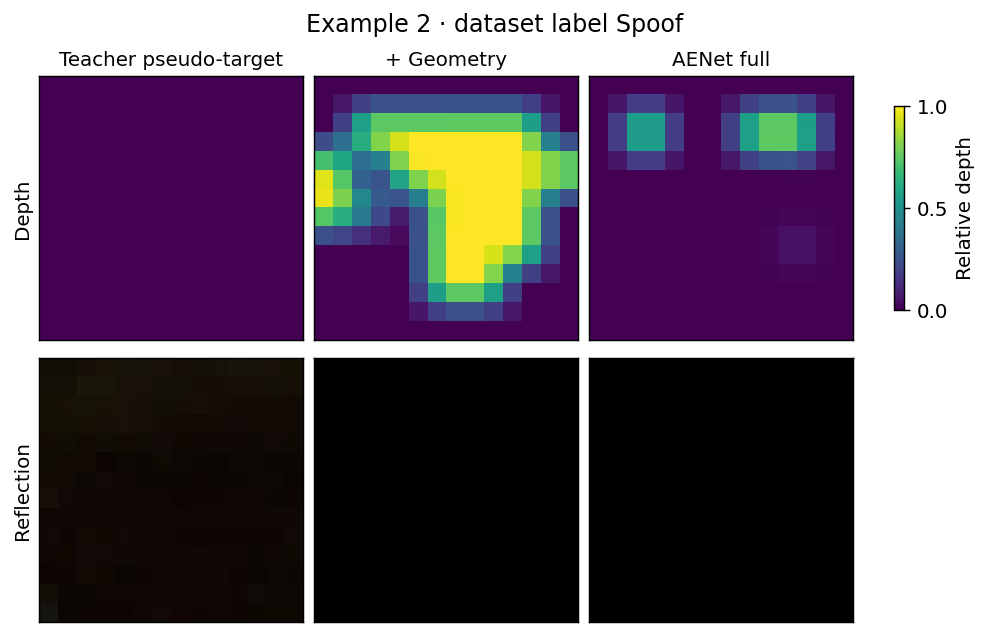

In [ ]:
if visual_auxiliary is not None and len(visual_gallery_cases) > 1:
    example_group, example_index = visual_gallery_cases[1]
    visual_example_decisions(2, example_group, example_index)
    visual_example_semantics(2, example_index)
    visual_example_geometry(2, example_index)
else:
    print("Example 2 unavailable for this report.")

#### 16\.2\.3 Example 3: Live

The baseline matches the recorded live label while AENet full predicts spoof. The sideways face orientation is already present in the original source image.

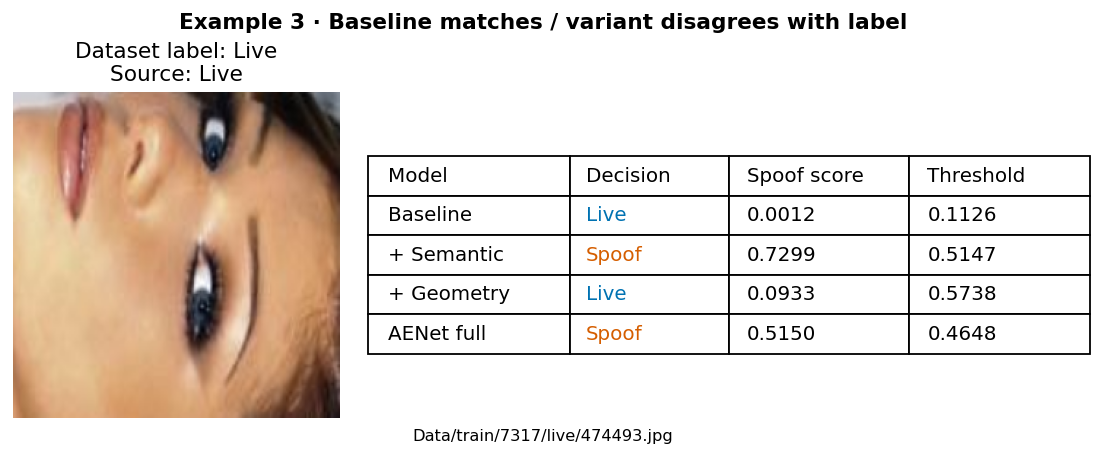

Example 3 · Data/train/7317/live/474493.jpg

Model,Target,Prediction,Annotation
+ Semantic,Source type,Live,Live
+ Semantic,Illumination,Live,Live
+ Semantic,Young,Present (0.706),Present
+ Semantic,No Beard,Present (0.698),Present
+ Semantic,Attractive,Absent (0.227),Present
AENet full,Source type,Live,Live
AENet full,Illumination,Live,Live
AENet full,Young,Present (0.850),Present
AENet full,No Beard,Present (0.814),Present
AENet full,Wearing Lipstick,Absent (0.490),Present


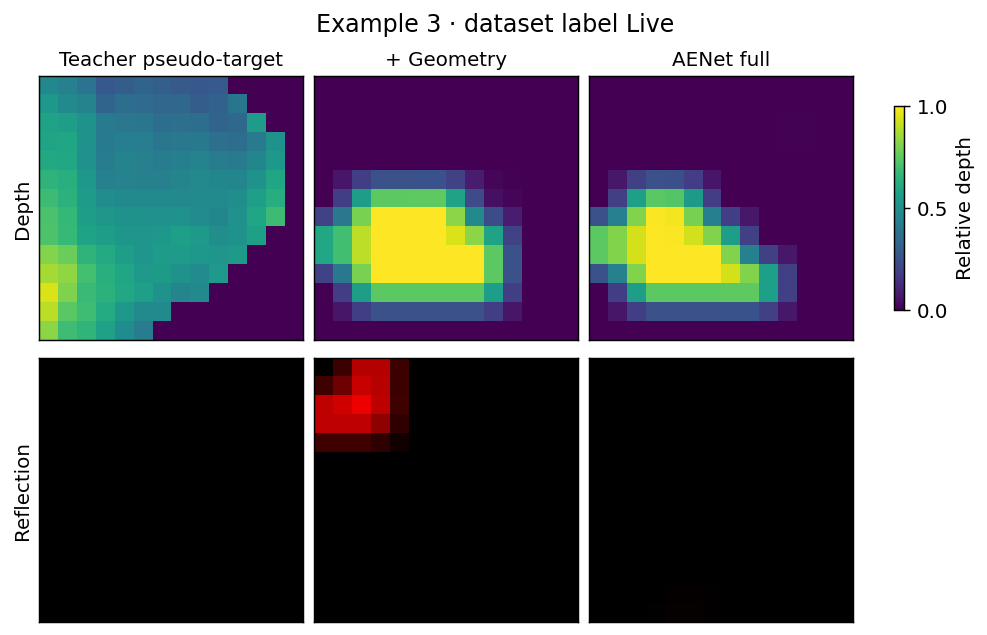

In [ ]:
if visual_auxiliary is not None and len(visual_gallery_cases) > 2:
    example_group, example_index = visual_gallery_cases[2]
    visual_example_decisions(3, example_group, example_index)
    visual_example_semantics(3, example_index)
    visual_example_geometry(3, example_index)
else:
    print("Example 3 unavailable for this report.")

#### 16\.2\.4 Example 4: Spoof

The baseline matches the recorded spoof label while AENet full predicts live.

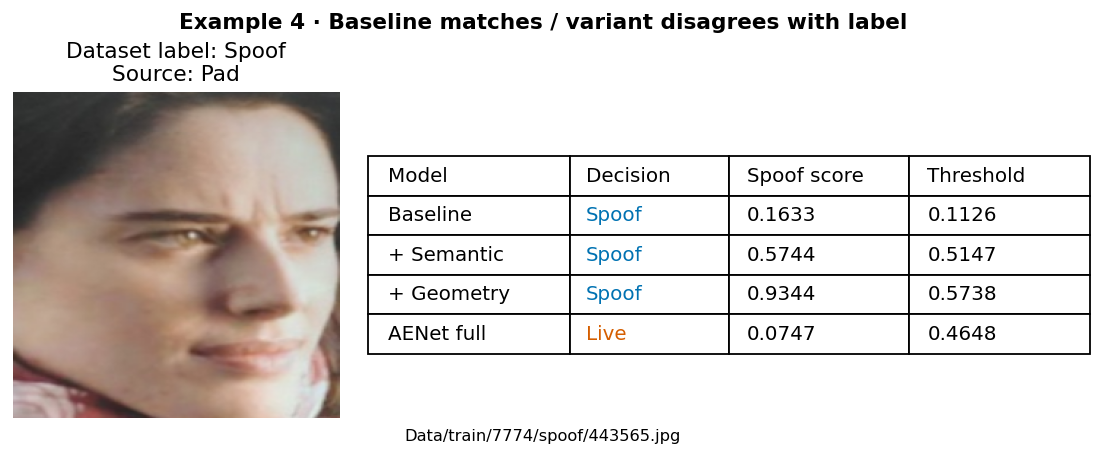

Example 4 · Data/train/7774/spoof/443565.jpg

Model,Target,Prediction,Annotation
+ Semantic,Source type,Live,Pad
+ Semantic,Illumination,Live,Back
+ Semantic,Young,Absent (0.346),Absent
+ Semantic,No Beard,Absent (0.283),Absent
+ Semantic,Black Hair,Absent (0.161),Absent
AENet full,Source type,Live,Pad
AENet full,Illumination,Live,Back
AENet full,No Beard,Present (0.671),Absent
AENet full,Young,Present (0.656),Absent
AENet full,Attractive,Absent (0.191),Absent


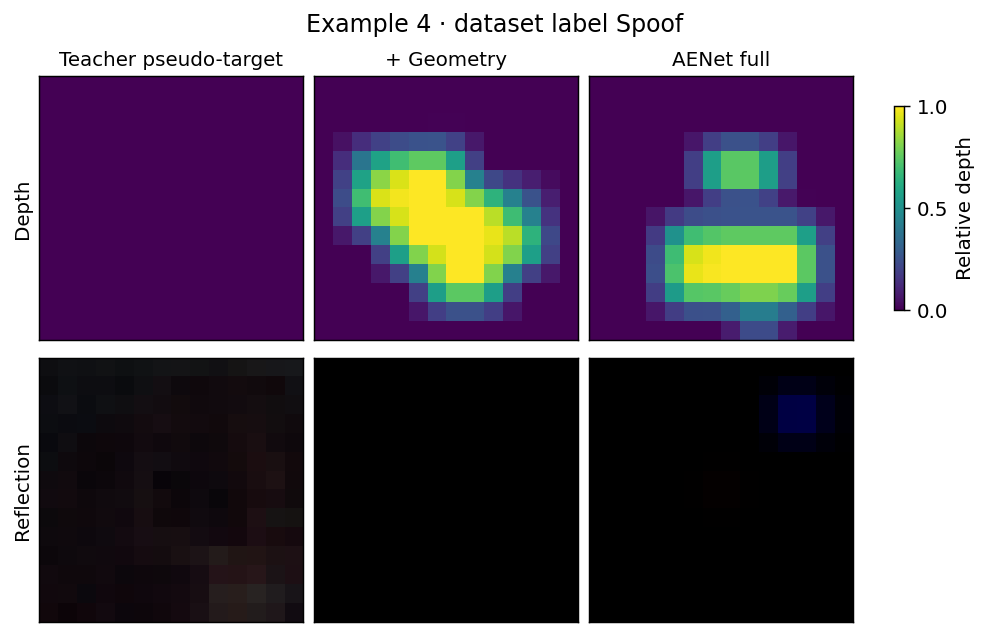

In [ ]:
if visual_auxiliary is not None and len(visual_gallery_cases) > 3:
    example_group, example_index = visual_gallery_cases[3]
    visual_example_decisions(4, example_group, example_index)
    visual_example_semantics(4, example_index)
    visual_example_geometry(4, example_index)
else:
    print("Example 4 unavailable for this report.")

#### 16\.2\.5 Example 5: Live

Both the baseline and AENet full predict spoof for this retained foreground-face crop, whose dataset label is live. These predictions use the original checkpoints. A wrong prediction alone does not identify the cause of the error.

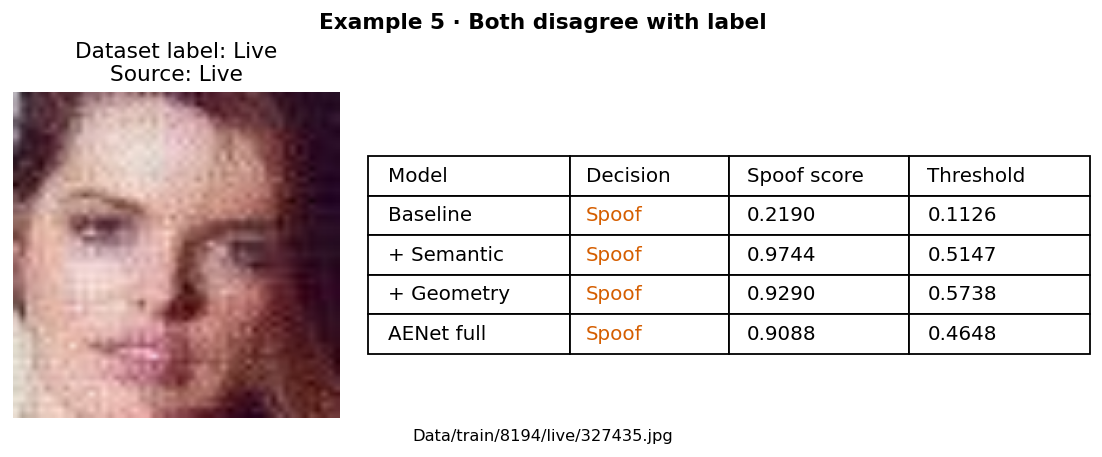

Example 5 · Data/train/8194/live/327435.jpg

Model,Target,Prediction,Annotation
+ Semantic,Source type,Live,Live
+ Semantic,Illumination,Normal,Live
+ Semantic,Blurry,Absent (0.402),Present
+ Semantic,Young,Absent (0.158),Present
+ Semantic,No Beard,Absent (0.076),Present
AENet full,Source type,Live,Live
AENet full,Illumination,Normal,Live
AENet full,Blurry,Absent (0.355),Present
AENet full,Young,Absent (0.141),Present
AENet full,No Beard,Absent (0.040),Present


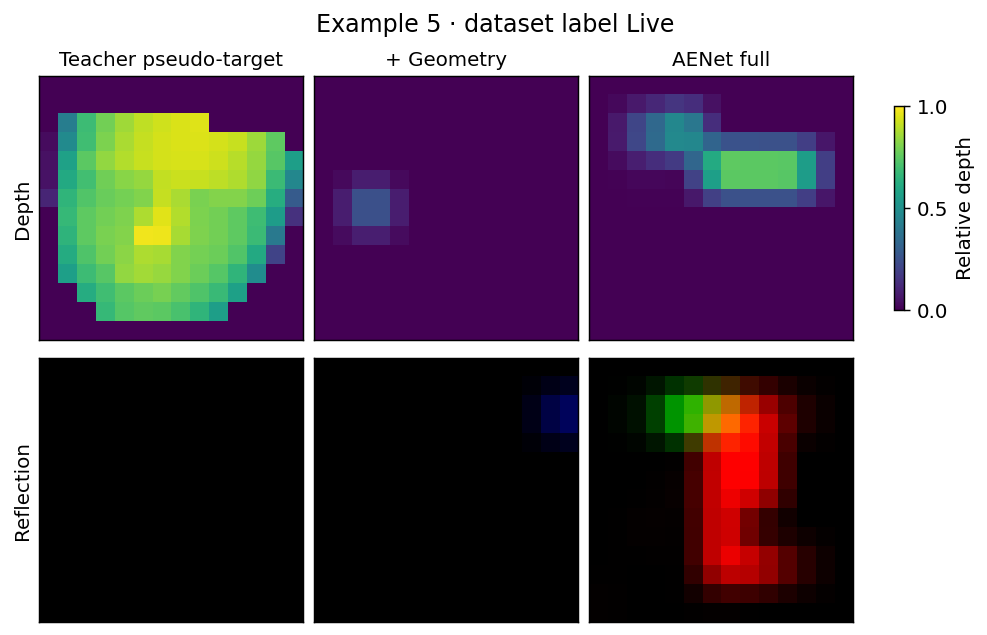

In [ ]:
if visual_auxiliary is not None and len(visual_gallery_cases) > 4:
    example_group, example_index = visual_gallery_cases[4]
    visual_example_decisions(5, example_group, example_index)
    visual_example_semantics(5, example_index)
    visual_example_geometry(5, example_index)
else:
    print("Example 5 unavailable for this report.")

#### 16\.2\.6 Example 6: Spoof

Both the baseline and AENet full predict live although the recorded label is spoof.

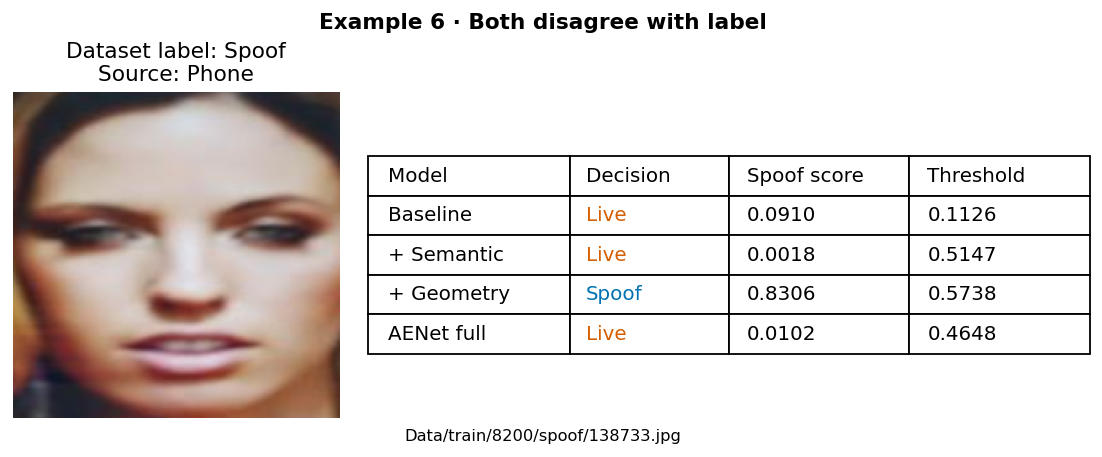

Example 6 · Data/train/8200/spoof/138733.jpg

Model,Target,Prediction,Annotation
+ Semantic,Source type,Live,Phone
+ Semantic,Illumination,Live,Strong
+ Semantic,No Beard,Present (0.947),Absent
+ Semantic,Young,Present (0.928),Absent
+ Semantic,Wearing Lipstick,Present (0.751),Absent
AENet full,Source type,Live,Phone
AENet full,Illumination,Live,Strong
AENet full,No Beard,Present (0.970),Absent
AENet full,Young,Present (0.942),Absent
AENet full,Wearing Lipstick,Present (0.838),Absent


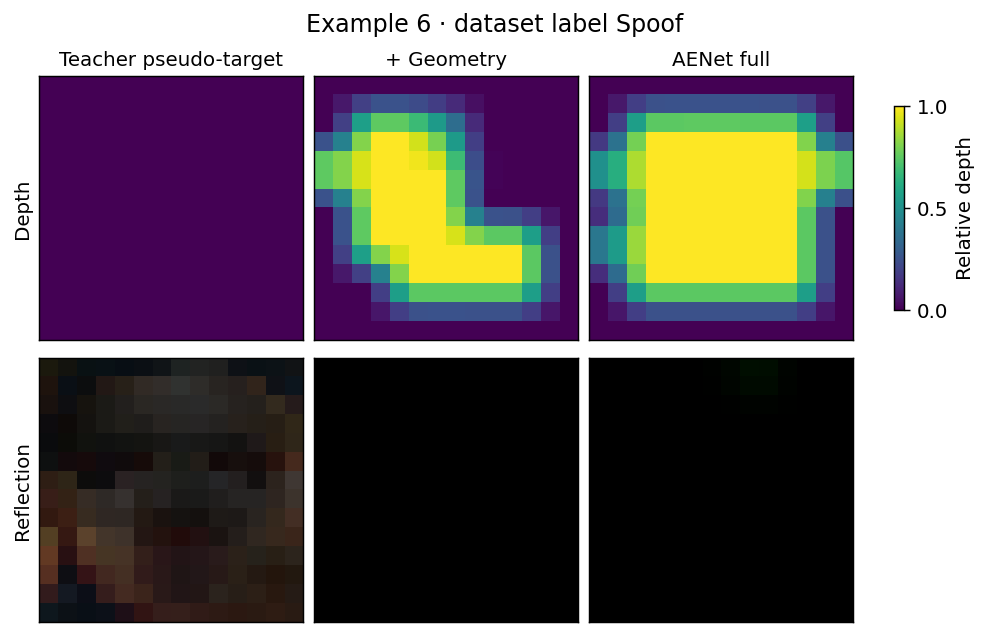

In [ ]:
if visual_auxiliary is not None and len(visual_gallery_cases) > 5:
    example_group, example_index = visual_gallery_cases[5]
    visual_example_decisions(6, example_group, example_index)
    visual_example_semantics(6, example_index)
    visual_example_geometry(6, example_index)
else:
    print("Example 6 unavailable for this report.")

### 16\.3 Reproduce the figures

The saved auxiliary report contains nine retained validation examples across the three model comparisons. The main gallery displays six of them for AENet full versus the baseline.

A separate GPU inference run generated auxiliary predictions on 26 November 2026 after verifying the complete checkpoints and source images. These figures use the original weights. By default, the notebook reads the saved report. Set `RUN_AUXILIARY_ANALYSIS = True` to regenerate it in a new output folder.

All nine source images and bounding boxes match their recorded checksums. Reconstructing each crop gives exactly the pixels saved in the report, and every example belongs to the retained validation split. This verifies those nine examples; it does not certify every remaining crop.

The four-model curves, error plots and gallery use the original checkpoints. Auxiliary predictions and reference maps were generated in a separate GPU inference run. Local inspect renders saved evidence without training.

The replay table reports score differences between the saved Colab predictions and this auxiliary inference runtime. All illustrated live/spoof decisions must agree at their original thresholds. The galleries retain the archived scores; auxiliary outputs are attributed to the new runtime.

In [ ]:
if visual_auxiliary is not None:
    display_table(
        [
            "Configuration",
            "Maximum absolute spoof-score difference",
            "Illustrated decisions",
        ],
        [
            [
                arm,
                f"{visual_auxiliary['models'][arm]['max_binary_score_difference']:.6g}",
                "Unchanged",
            ]
            for arm in VISUAL_ARMS
        ],
    )

Configuration,Maximum absolute spoof-score difference,Illustrated decisions
binary-classification,0.000834301,Unchanged
binary-semantic,0.00107276,Unchanged
binary-geometric,0.00124669,Unchanged
aenet-full,0.00031209,Unchanged


## 17\. Checkpoints and saved predictions

Each archived epoch retains model weights, optimizer state, random-number-generator (RNG) state and training position with a checksum receipt. The optimizer state allows the same update process to continue; RNG state preserves the random sequence needed for compatible resume. Each validation prediction row records the source image, its live/spoof label and its spoof score. Those rows can be reused to compare thresholds or calculate errors for a particular attack type without running the same model on those images again.

[export_liveness_checkpoint.py](https://drive.google.com/file/d/1kRVjudPB-N5AXlJggK77KPnaC8pVrPLP/view?usp=drivesdk) exports an archived epoch for inference. Supply two paths:

- `--receipt PATH`: input JSON receipt for the archived epoch.
- `--output PATH`: destination file for the exported inference checkpoint.

[score_liveness_image_split.py](../scripts/evaluation/score_liveness_image_split.py) reloads the selected model with its saved preprocessing and threshold. Reusing a score file is valid only for the same inputs and predictions; an analysis requiring different inputs may still need new inference.


## 18\. Implementation checks and limits

[Comparison with the authors' code](https://drive.google.com/drive/folders/1VY_8M1cg0zVGV-_i0zjNHe7M2EMvxIqE) uses matched inputs to check preprocessing, predictions, metrics and one optimizer update within recorded tolerances. These checks establish implementation behavior on those inputs, not general accuracy.

[Teacher comparisons](https://drive.google.com/drive/folders/1RKgz7nLLMnhvffysO_7G5kTDbOFOGFDD) compare original TensorFlow and converted PyTorch PRNet/reflection outputs on the same images. Their grids remain pseudo-targets.

Public-test and camera results assess the trained checkpoint on their declared inputs. Prior public-test exposure, unequal final training budgets and unverified cross-dataset/source-video independence limit generalization claims. Historical comparisons retain their original runtime/source attribution.


## 19\. Research references

- Zhang, Y. et al. (2020). [CelebA-Spoof: Large-Scale Face Anti-Spoofing Dataset with Rich Annotations](https://arxiv.org/abs/2007.12342v3). ECCV. Dataset and AENet framework; [authors’ source code](https://github.com/ZhangYuanhan-AI/CelebA-Spoof).
- Feng, Y. et al. (2018). [Joint 3D Face Reconstruction and Dense Alignment with Position Map Regression Network](https://github.com/yfeng95/PRNet). ECCV. Source implementation for the PRNet depth teacher.
- Zhang, X. et al. (2018). [Single Image Reflection Separation with Perceptual Losses](https://github.com/ceciliavision/perceptual-reflection-removal). CVPR. Source implementation for the reflection teacher.
